# Module 1 · Partie 7 : TP guidé, Homework 1 (acides gras saturés du lait)

> *Multivaried Analysis 2 : Data Mining & Machine Learning*, Prof. Hélène Soyeurt, 2026-2027.

**Organisation du TP (4 parties)**

| Partie | Source | Contenu |
|---|---|---|
| **A** | `Homework1/homework1.R` (script du homework) | démarche complète en 11 étapes : univariée → 10 features → sélection → Lasso sur tout le spectre → outliers → modèle final |
| **B** | `Homework1/fatty_acids_20201006.Rmd` (**correction officielle** de H. Soyeurt, rendu Word : `.docx`) | nettoyage du spectre (CV), réduction de la colinéarité (une feature par région), Lasso comme outil de sélection |
| **C** | `Homework1/2026_AMV2_module1.R` (script de la séance TP 2026) | exploration rapide, boucle `descr`, Lasso/Ridge sur le spectre complet |
| **D** | : | comparaison des démarches A et B |

**Objectif du TP (partie A)**

Construire une **équation de prédiction de la teneur en acides gras saturés (SAT, g/dl de lait)** à partir du **spectre moyen infrarouge (FT-MIR)** du lait, en appliquant **toute la démarche du module 1** :

1. lecture du fichier ;
2. statistiques descriptives ;
3. transformation de la variable à expliquer ;
4. régression univariée sur le point spectral le plus corrélé ;
5. analyse des résidus ;
6. régression multivariée sur les 10 points les plus corrélés ;
7. sélection de variables (toutes les combinaisons, backward, forward, stepwise) ;
8. régression pénalisée (Lasso) sur le spectre entier ;
9. modèle final : variables du Lasso, détection des outliers ;
10. ajustement final sans outliers + backward ;
11. sauvegarde de la meilleure équation.

**Mode d'emploi**

Pour chaque étape :

- lis l'**énoncé** ;
- écris ton code dans la cellule **« À toi de jouer ! »** ;
- compare avec la **solution repliable** (Voir la solution) et réponds aux **questions d'interprétation** ;
- exécute ensuite la cellule **Point de contrôle** : elle (re)crée proprement les objets dont l'étape suivante a besoin. Ainsi, même si ton code a échoué ou si tu as sauté une étape, la suite du TP fonctionne.

> Les noms d'objets (`fa`, `y`, `x`, `reg1`, `reg1b`, `reg2`, `fmla`, `lasso.mod`, `best`…) sont ceux du script `homework1.R` : utilise-les pour que les points de contrôle et la suite restent cohérents.

## 0. Préparation

Chargement des packages utilisés par le homework :

- `summarytools` (`descr`), `pander` (tableaux), `knitr` (`kable`), `MASS` (`stepAIC`), `olsrr` (`ols_step_all_possible`), `glmnet` (Lasso).

> **`pander()` dans Jupyter** : `pander` produit du texte au format Markdown. Dans RStudio/RMarkdown, il est rendu en joli tableau ; dans Jupyter, il s'affiche en texte brut. On définit donc une petite fonction `pander_md()` qui demande à Jupyter d'**afficher ce Markdown** proprement. Dans RStudio, utilise simplement `pander()`.

In [1]:
suppressPackageStartupMessages({
  library(summarytools)
  library(pander)
  library(knitr)
  library(MASS)
  library(olsrr)
  library(glmnet)
})
options(repr.plot.width = 10, repr.plot.height = 6)

# Affiche la sortie de pander() comme du Markdown rendu dans Jupyter
pander_md <- function(obj, ...) {
  IRdisplay::display_markdown(paste(capture.output(pander(obj, ...)), collapse = "\n"))
}

# setwd("~/Documents/GBX/MA2/AM2/Module1/Homework1")   # dans RStudio ; inutile dans Jupyter
# Ici le notebook tourne dans Module1/Cours/ : le fichier est dans ../Homework1/

---

# PARTIE A : la démarche du script `homework1.R`

## Étape 1 : lecture du fichier de données

**Énoncé**

1. Lis le fichier `../Homework1/fatty_acids.csv` dans un objet `fa`. Le séparateur est `;` et **la première ligne contient les noms des colonnes** (contrairement à `lactoferrin.csv`).
2. Affiche ses dimensions et les noms des 6 premières colonnes.
3. Décris la structure du fichier : que contiennent les colonnes 1, 2, 3, 4 et 5 à 1064 ?

In [2]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
fa <- read.table(file = "../Homework1/fatty_acids.csv", sep = ";", header = TRUE)
dim(fa)              # 485 lignes, 1064 colonnes
names(fa)[1:6]       # "sampleID" "SAT" "MONO" "POLY" "X1" "X2"
# str(fa)            # (très long : 1064 colonnes)
```

Structure : colonne 1 = `sampleID`, 2 = `SAT` (acides gras saturés), 3 = `MONO` (mono-insaturés), 4 = `POLY` (poly-insaturés), colonnes **5 à 1064** = les **1060 points du spectre**. Comme `header = TRUE`, R a nommé les points spectraux `X1` … `X1060` (un nom de colonne ne peut pas commencer par un chiffre, R ajoute donc un `X`).

</details>

**Question** : quel est le décalage entre le numéro d'un point spectral et son numéro de colonne dans `fa` ? Pourquoi est-ce important pour la suite ?

<details>
<summary><b>Voir la réponse</b></summary>

Le point spectral `k` est dans la colonne `k + 4` (4 colonnes avant le spectre : sampleID, SAT, MONO, POLY). Dans la résolution de la lactoferrine, le décalage était **+1** (seulement l'ID avant le spectre). Ici, il faudra écrire `fa[, ordercorrelation[1060] + 4]`.

</details>

In [3]:
# Point de contrôle : objets nécessaires pour la suite
fa <- read.table(file = "../Homework1/fatty_acids.csv", sep = ";", header = TRUE)
dim(fa)

[1]  485 1064

## Étape 2 : statistiques descriptives

**Énoncé**

1. Crée un data.frame `y` contenant uniquement la colonne SAT et nomme sa colonne `"SAT"`.
2. Calcule les statistiques descriptives avec `descr(y, transpose = TRUE)` (package `summarytools`) dans un objet `stat` et affiche-les.
3. Extrais dans des objets : la variance, l'écart-type, l'étendue (*range*), le coefficient de variation et l'écart interquartile.
4. Trace l'histogramme de SAT (20 classes, barres bleues, axe x « Saturated fatty acids (g/dl of milk) », sans titre).

In [4]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
y <- data.frame(fa[, 2])
names(y) <- c("SAT")
stat <- descr(y, transpose = TRUE)
pander_md(stat)                    # dans RStudio : pander(stat)

variance      <- (stat$Std.Dev)^2
SD            <- stat$Std.Dev
range         <- stat$Max - stat$Min
CV            <- stat$CV
interquartile <- stat$IQR
c(variance = variance, SD = SD, range = range, CV = CV, IQR = interquartile)

par(mfrow = c(1, 1))
hist(y$SAT, breaks = 20, col = "blue", xlab = "Saturated fatty acids (g/dl of milk)", main = NULL)
```

Résultats attendus : moyenne ≈ 2.40 g/dl, médiane ≈ 2.15, écart-type ≈ 0.86, min ≈ 0.19, max ≈ 5.49, CV ≈ 0.36 (36 %), IQR ≈ 0.96, *skewness* ≈ 0.99.

`descr()` renvoie le CV sous forme de **rapport** (0.36), pas en pourcentage. Et `range` écrase ici la fonction R `range()` le temps de la session ; c'est le nom choisi dans le homework, mais en pratique on évite de donner à un objet le nom d'une fonction.

</details>

**Questions d'interprétation**

1. La distribution de SAT est-elle symétrique ? Compare moyenne et médiane.
2. Les valeurs extrêmes (≈ 0.19 et ≈ 5.5 g/dl) te semblent-elles plausibles ? Quelle démarche du cours (étape *Data validation*) faudrait-il appliquer ?

<details>
<summary><b>Voir la réponse</b></summary>

1. Moyenne (2.40) > médiane (2.15) et skewness ≈ 1 > 0 : la distribution est **asymétrique à droite** (queue vers les grandes valeurs ; cf. mode < médiane < moyenne). L'asymétrie est toutefois bien plus faible que pour la lactoferrine (skewness 3.1).
2. Il faut **comparer avec la littérature** (teneurs habituelles en acides gras saturés du lait) et **connaître l'origine des données** (méthode de référence, répétabilité, nombre de labos…). Une valeur de 0.19 g/dl est très basse : à vérifier (erreur d'encodage, échantillon particulier ?). On ne supprime pas une valeur extrême sans raison : **une valeur extrême n'est pas forcément un outlier**.

</details>



| &nbsp;  | Mean  | Std.Dev |  Min  |  Q1  | Median |  Q3   |  Max  |
|:-------:|:-----:|:-------:|:-----:|:----:|:------:|:-----:|:-----:|
| **SAT** | 2.403 | 0.8576  | 0.188 | 1.85 | 2.151  | 2.811 | 5.489 |

Table: Table continues below

 

| &nbsp;  |  MAD   |  IQR  |   CV   | Skewness | SE.Skewness | Kurtosis |
|:-------:|:------:|:-----:|:------:|:--------:|:-----------:|:--------:|
| **SAT** | 0.6257 | 0.961 | 0.3569 |  0.9888  |   0.1109    |  0.8159  |

Table: Table continues below

 

| &nbsp;  | N.Valid |  N  | Pct.Valid |
|:-------:|:-------:|:---:|:---------:|
| **SAT** |   485   | 485 |    100    |


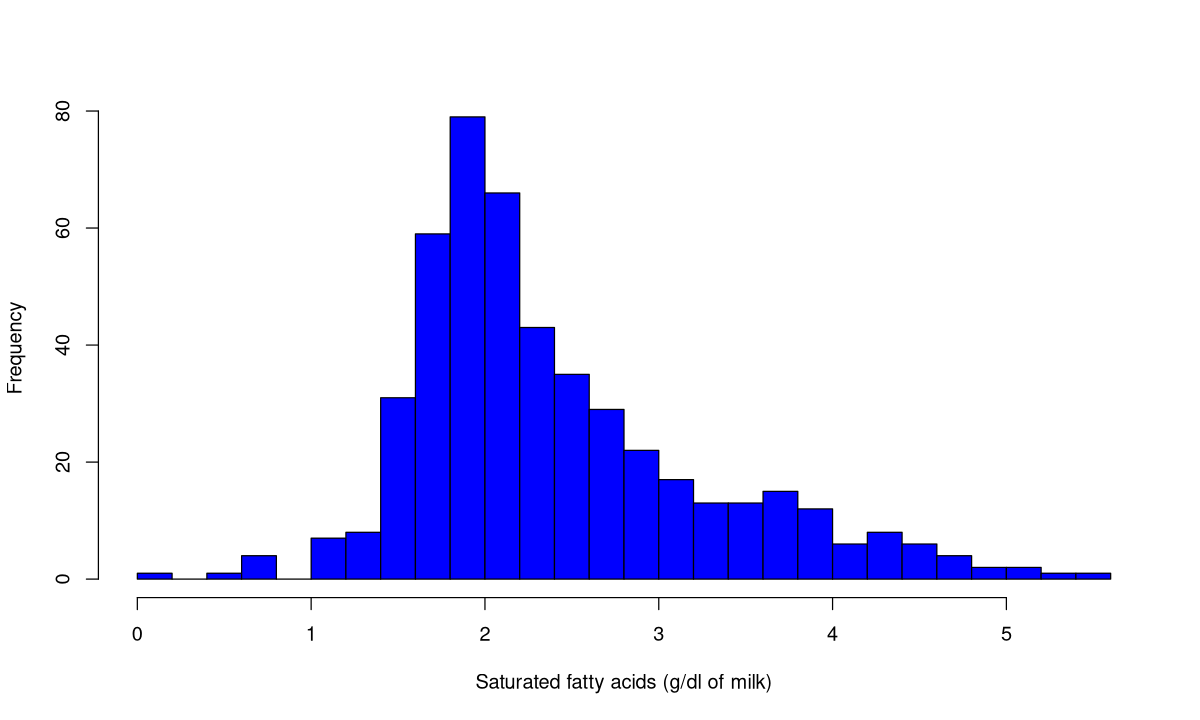

In [5]:
# Point de contrôle
y <- data.frame(fa[, 2])
names(y) <- c("SAT")
stat <- descr(y, transpose = TRUE)
pander_md(stat)
par(mfrow = c(1, 1))
hist(y$SAT, breaks = 20, col = "blue", xlab = "Saturated fatty acids (g/dl of milk)", main = NULL)

## Étape 3 : transformations de la variable à expliquer

**Énoncé**

Trace, l'un au-dessus de l'autre (3 lignes, 1 colonne), les histogrammes (30 classes) de `SAT`, `log10(SAT)` et `sqrt(SAT)`. Quelle distribution semble la plus symétrique ?

In [6]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
par(mfrow = c(3, 1))
hist(y$SAT,        breaks = 30, col = "blue", main = NULL, xlab = "SAT")
hist(log10(y$SAT), breaks = 30, col = "blue", main = NULL, xlab = "log10(SAT)")
hist(sqrt(y$SAT),  breaks = 30, col = "blue", main = NULL, xlab = "sqrt(SAT)")
par(mfrow = c(1, 1))
```

Visuellement, `sqrt` et `log10` réduisent la queue à droite, mais `log10` **étire fortement la queue gauche** (les quelques très petites valeurs, ≈ 0.19, deviennent ≈ −0.7). Comme le rappelle la résolution de la lactoferrine, **l'intérêt d'une transformation se confirme lors de l'analyse des résidus** (étape 5), pas seulement sur l'histogramme de y.

</details>

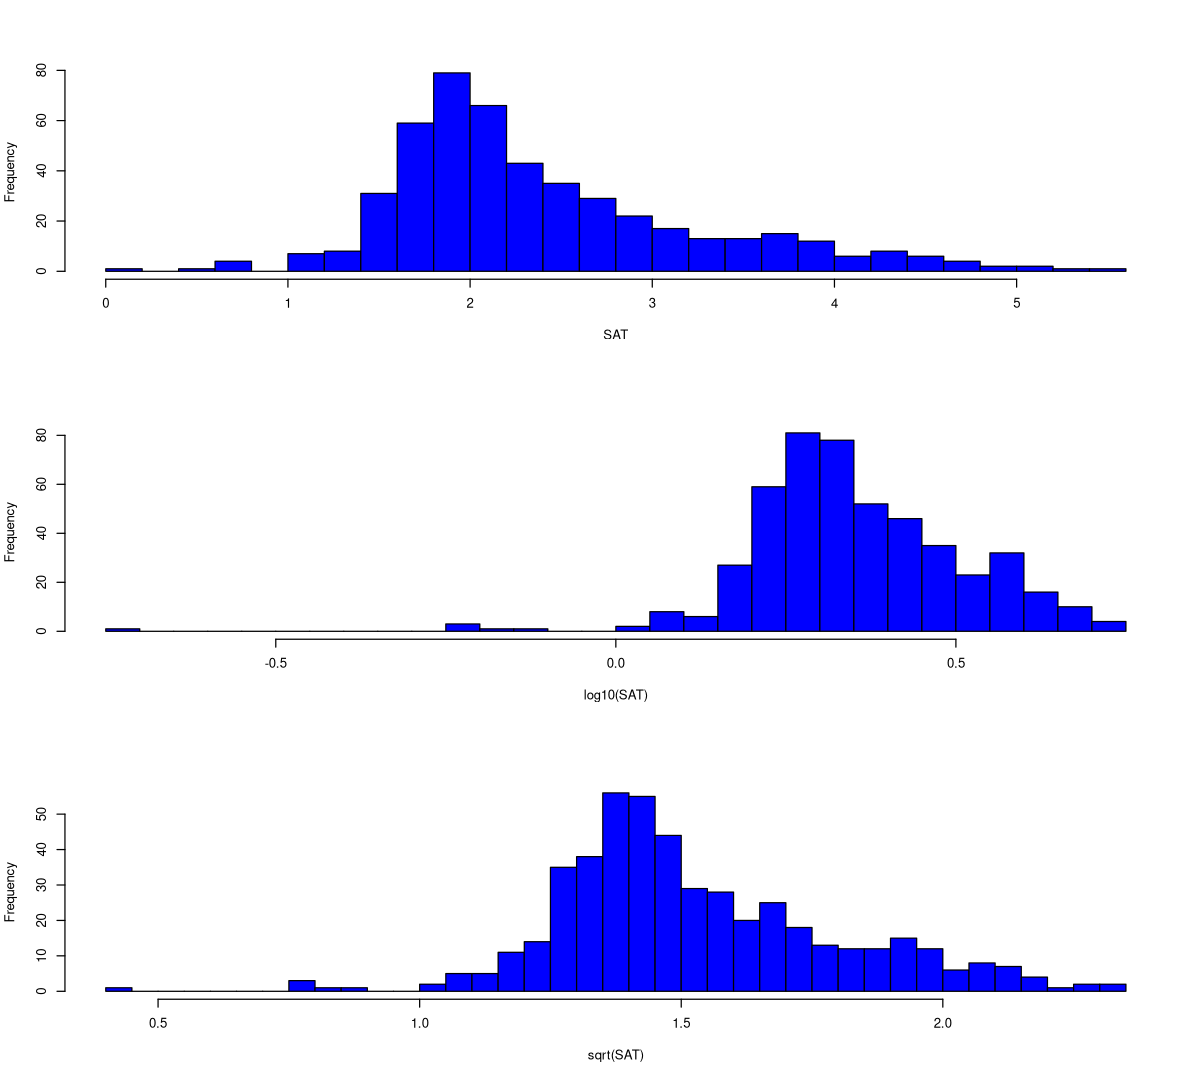

In [7]:
# Point de contrôle (graphique uniquement, aucun objet nouveau)
options(repr.plot.height = 9)
par(mfrow = c(3, 1))
hist(y$SAT,        breaks = 30, col = "blue", main = NULL, xlab = "SAT")
hist(log10(y$SAT), breaks = 30, col = "blue", main = NULL, xlab = "log10(SAT)")
hist(sqrt(y$SAT),  breaks = 30, col = "blue", main = NULL, xlab = "sqrt(SAT)")
par(mfrow = c(1, 1))
options(repr.plot.height = 6)

## Étape 4 : régression univariée

**Énoncé**

1. Calcule la corrélation entre **chaque point spectral** (colonnes 5:1064) et SAT. Astuce plus efficace que la méthode de la résolution : `cor(fa[, 5:1064], fa[, 2])` calcule directement les 1060 corrélations avec y (au lieu d'une matrice 1061 × 1061). Garde un vecteur nommé `correlation`.
2. Trace le spectre de corrélation (ligne rouge).
3. Trouve la corrélation maximale **en valeur absolue** (`cormax`) et le nom du point correspondant (`namemax`).
4. Classe les points par corrélation absolue croissante (`ordercorrelation`), puis sélectionne dans `x` le point le plus corrélé (décalage de colonne !).
5. Transforme `y` et `x` en matrices, ajuste `reg1 <- lm(y ~ x)` et affiche le résumé.
6. Calcule `R2_1`, `SEP_1` et le R² ajusté `adjR2_1` (k = 1) comme dans la résolution.

In [8]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
correlation <- cor(fa[, 5:1064], fa[, 2])     # matrice 1060 x 1 : spectre vs SAT
correlation <- correlation[, 1]               # -> vecteur nommé
par(mfrow = c(1, 1))
plot(correlation, type = "l", col = "red", xlab = "Spectral wavenumber")

cormax  <- max(abs(correlation))
namemax <- names(correlation[abs(correlation) == cormax])
c(cormax = cormax); namemax                   # 0.969 pour X213

ordercorrelation <- order(abs(correlation))
x <- fa[, ordercorrelation[1060] + 4]         # +4 : 4 colonnes avant le spectre
y <- as.matrix(y$SAT)
x <- as.matrix(x)
reg1 <- lm(y ~ x)
pander_md(summary(reg1))                      # RStudio : panderOptions("table.style","simple"); pander(summary(reg1))

R2_1    <- cor(y, reg1$fitted.values)^2
SEP_1   <- sqrt(sum((reg1$fitted.values - y)^2) / reg1$df.residual)
k       <- 1                                  # nb de paramètres estimés hors intercept
adjR2_1 <- 1 - ((1 - R2_1) * (length(y) - 1)) / (length(y) - k - 1)
c(R2 = R2_1, SEP = SEP_1, adjR2 = adjR2_1)
```

Résultats attendus : le point le plus corrélé est **X213** (r ≈ 0.97) ; **R² ≈ 0.939**, R² ajusté ≈ 0.939, **SEP ≈ 0.21 g/dl** (= *Residual standard error* du résumé), 483 degrés de liberté.

Le homework utilise `abs()` dans `namemax` : c'est plus sûr que la version de la résolution (`correlation == cormax`), qui échoue si la corrélation la plus forte est **négative**.

</details>

**Questions d'interprétation**

1. Pourquoi `x <- fa[, ordercorrelation[1060] + 4]` sélectionne-t-il le point le plus corrélé ?
2. Le R² vaut ≈ 0.94 avec **un seul** point spectral, contre 0.26 pour la lactoferrine. Comment l'expliques-tu ?
3. Que représente SEP et dans quelle unité est-il exprimé ? Compare-le à l'écart-type de SAT.

<details>
<summary><b>Voir la réponse</b></summary>

1. `order()` renvoie les **positions** des corrélations triées par ordre croissant de valeur absolue : la 1060e (dernière) position est donc celle du point le plus corrélé. On ajoute 4 pour passer d'un numéro de point spectral à un numéro de colonne de `fa`.
2. La matière grasse (et donc les acides gras saturés, composants majeurs) absorbe fortement dans le moyen infrarouge (liaisons C–H, C=O des esters) : le signal est **direct et intense**. La lactoferrine est une protéine mineure (≈ 100 mg/L), son signal est faible et noyé dans celui des autres constituants.
3. SEP = écart-type des résidus (racine de la SCE résiduelle divisée par les degrés de liberté n − k − 1), **dans l'unité de y** (g/dl). 0.21 g/dl à comparer à l'écart-type de SAT, 0.86 g/dl : l'erreur de prédiction est environ 4 fois plus petite que la variabilité naturelle. Rappel : 0 ≤ RMSE ≤ s_y.

</details>

namemax  cormax      R2     SEP   adjR2 
 "X213" "0.969" "0.939" "0.212" "0.939"

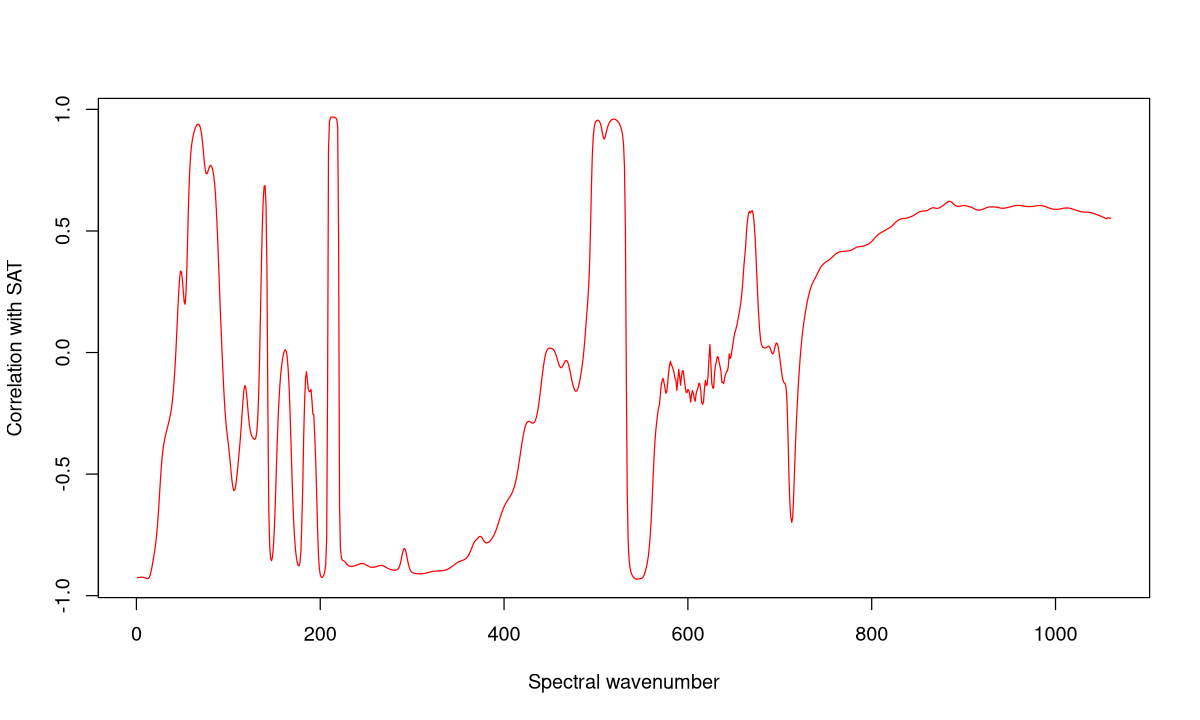

In [9]:
# Point de contrôle
correlation <- cor(fa[, 5:1064], fa[, 2])[, 1]
cormax  <- max(abs(correlation))
namemax <- names(correlation[abs(correlation) == cormax])
ordercorrelation <- order(abs(correlation))
y <- as.matrix(fa$SAT)
x <- as.matrix(fa[, ordercorrelation[1060] + 4])
reg1 <- lm(y ~ x)
R2_1    <- cor(y, reg1$fitted.values)^2
SEP_1   <- sqrt(sum((reg1$fitted.values - y)^2) / reg1$df.residual)
adjR2_1 <- 1 - ((1 - R2_1) * (length(y) - 1)) / (length(y) - 1 - 1)
plot(correlation, type = "l", col = "red", xlab = "Spectral wavenumber", ylab = "Correlation with SAT")
c(namemax = namemax, cormax = round(cormax, 3), R2 = round(R2_1, 3), SEP = round(SEP_1, 3), adjR2 = round(adjR2_1, 3))

## Étape 5 : analyse des résidus

**Énoncé**

1. Affiche les 4 graphes de diagnostic de `reg1` (`par(mfrow = c(2, 2))`).
2. Teste la normalité des résidus avec le test de Shapiro-Wilk.
3. Affiche la distance de Cook seule (`which = 4`).
4. Teste les transformations : ajuste `reg1b <- lm(log10(y) ~ x)` et `reg1c <- lm(sqrt(y) ~ x)` et compare les p-valeurs du test de Shapiro.

In [10]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
par(mfrow = c(2, 2))
plot(reg1)
pander_md(shapiro.test(resid(reg1)))
par(mfrow = c(1, 1))
plot(reg1, which = 4)

reg1b <- lm(log10(y) ~ x)
pander_md(shapiro.test(resid(reg1b)))
reg1c <- lm(sqrt(y) ~ x)
pander_md(shapiro.test(resid(reg1c)))
```

p-valeurs attendues du test de Shapiro : **y brut ≈ 0.028**, **log10(y) ≈ 1e-26**, **sqrt(y) ≈ 5e-7**.

</details>

**Questions d'interprétation**

1. Pour y brut, p ≈ 0.028 < 0.05 : que conclut-on formellement ? Cette conclusion est-elle grave avec n = 485 ?
2. Pourquoi la transformation log10, qui était la bonne pour la lactoferrine, est-elle ici la **pire** ?
3. Quelle variable à expliquer gardes-tu pour la suite ?

<details>
<summary><b>Voir la réponse</b></summary>

1. On rejette H0 (« les résidus suivent une loi normale ») au seuil de 5 %. Mais avec un grand n, le test de Shapiro détecte de **très petits écarts** à la normalité ; il faut donc **regarder aussi les graphes** : si le Q-Q plot est presque aligné et que Residuals vs Fitted tourne autour de 0 sans entonnoir, l'écart est mineur.
2. La lactoferrine était **très** asymétrique à droite (skewness 3.1) : le log la symétrisait. SAT n'est que modérément asymétrique et possède quelques **très petites valeurs** : le log les envoie loin vers −∞ (log10(0.19) ≈ −0.72), ce qui crée une longue queue à gauche dans les résidus. **Une transformation n'est pas universelle : elle se valide sur les résidus.**
3. On garde **SAT brut** (c'est le choix du homework : toutes les étapes suivantes utilisent `y`). Les points mis en évidence par la distance de Cook seront traités à l'étape 9.

</details>

modele,shapiro_W,shapiro_p
<chr>,<dbl>,<dbl>
y,0.9932164,2.776613e-02
log10(y),0.7451178,1.206136e-26
sqrt(y),0.9765073,4.875840e-07


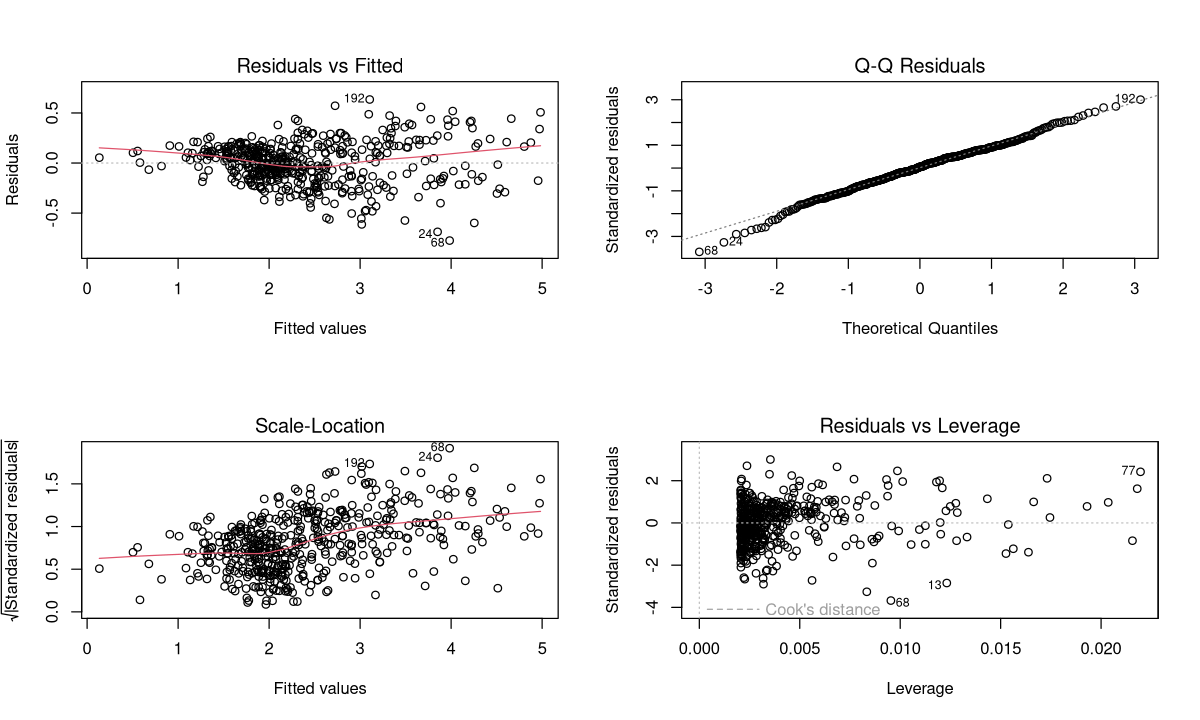

In [11]:
# Point de contrôle
reg1b <- lm(log10(y) ~ x)
reg1c <- lm(sqrt(y) ~ x)
par(mfrow = c(2, 2))
plot(reg1)
par(mfrow = c(1, 1))
data.frame(modele = c("y", "log10(y)", "sqrt(y)"),
           shapiro_W = sapply(list(reg1, reg1b, reg1c), function(m) shapiro.test(resid(m))$statistic),
           shapiro_p = sapply(list(reg1, reg1b, reg1c), function(m) shapiro.test(resid(m))$p.value))

## Étape 6 : régression multivariée avec les 10 features les plus corrélées

**Énoncé**

1. Mets dans `x` (matrice) les **10 points spectraux les plus corrélés** avec SAT.
2. Ajuste `reg2 <- lm(y ~ x)`, affiche les 4 graphes de diagnostic, le test de Shapiro, la distance de Cook et le résumé.
3. Compare R² et R² ajusté avec ceux de `reg1`.

In [12]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
x <- fa[, ordercorrelation[1051:1060] + 4]    # positions 1051 à 1060 = les 10 plus corrélées
x <- as.matrix(x)
reg2 <- lm(y ~ x)
par(mfrow = c(2, 2))
plot(reg2)
pander_md(shapiro.test(resid(reg2)))
par(mfrow = c(1, 1))
plot(reg2, which = 4)
pander_md(summary(reg2))
```

R² ≈ **0.955** (contre 0.939 avec 1 point) : le gain est faible pour 9 variables de plus.

</details>

**Questions d'interprétation**

1. Regarde les noms des 10 features retenues. Que remarques-tu ? Quelle conséquence sur les coefficients ?
2. Pourquoi le gain de R² est-il si faible ?

<details>
<summary><b>Voir la réponse</b></summary>

1. Ce sont des points **adjacents**, regroupés dans deux zones seulement (X211 à X218 et X519-X520) : ils sont **très corrélés entre eux** (r ≈ 0.97 à 1.00, colinéarité). Les coefficients deviennent grands, de signes alternés, avec de grandes erreurs standard ; leur interprétation individuelle n'a pas de sens.
2. Des points adjacents portent presque **la même information** : en ajouter n'apporte presque rien de neuf. Sélectionner les variables uniquement sur leur corrélation avec y est **intuitif mais naïf** : il faudrait des variables **complémentaires**. D'où les méthodes de sélection (étape 7) et le Lasso (étape 8).

</details>

In [13]:
# Point de contrôle
x <- as.matrix(fa[, ordercorrelation[1051:1060] + 4])
reg2 <- lm(y ~ x)
colnames(x)
round(cor(x), 2)[1:5, 1:5]      # aperçu de la colinéarité
c(R2_reg1 = summary(reg1)$r.squared, R2_reg2 = summary(reg2)$r.squared,
  adjR2_reg2 = summary(reg2)$adj.r.squared)

[1] "X218" "X520" "X519" "X217" "X211" "X216" "X215" "X212" "X214" "X213"

,X218,X520,X519,X217,X211
X218,1.00,0.97,0.97,1.00,0.99
X520,0.97,1.00,1.00,0.98,0.97
X519,0.97,1.00,1.00,0.98,0.98
X217,1.00,0.98,0.98,1.00,0.99
X211,0.99,0.97,0.98,0.99,1.00


R2_reg1    R2_reg2 adjR2_reg2 
 0.9392331  0.9545736  0.9536152

## Étape 7 : sélection de variables parmi les 10 features

**Énoncé**

1. Construis automatiquement la formule `y ~ x[,1] + x[,2] + ... + x[,10]` avec `paste0()` et `as.formula()` (objet `fmla`).
2. Ajuste `model <- lm(fmla)` puis lance `ols_step_all_possible(model)` (package `olsrr`). Combien de modèles sont testés ?
3. Construis un tableau `table` avec `n`, `predictors`, `rsquare`, `adjr`, `aic` (dans les versions récentes d'olsrr, ces colonnes sont dans `selection$result`), puis affiche les 5 meilleurs modèles selon l'AIC.
4. Fais une sélection **backward** avec `stepAIC()` (package MASS), puis **forward** et **stepwise** en partant du modèle vide `lm(y ~ 1)` avec `scope = list(upper = model1, lower = model2)`. Pour ne pas afficher toutes les étapes, ajoute `trace = 0`.
5. Compare les formules finales des trois méthodes.

In [14]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
xnam <- paste0("x[,", 1:10, "]")
fmla <- as.formula(paste("y ~ ", paste(xnam, collapse = "+")))
fmla

model <- lm(fmla)
selection <- ols_step_all_possible(model)          # 2^10 - 1 = 1023 modèles
# versions récentes d'olsrr : les statistiques sont dans selection$result
table <- data.frame(selection$result$n, selection$result$predictors, selection$result$rsquare,
                    selection$result$adjr, selection$result$aic)
names(table) <- c("n", "predictors", "rsquare", "adjr", "aic")
rankingAIC <- order(table$aic)
kable(table[rankingAIC[1:5], ], digits = 3)

backward <- stepAIC(lm(fmla), direction = "backward", trace = 0)
model1 <- lm(fmla)          # modèle complet (borne supérieure)
model2 <- lm(y ~ 1)         # modèle vide : intercept seul (borne inférieure)
forward  <- stepAIC(model2, direction = "forward", scope = list(upper = model1, lower = model2), trace = 0)
stepwise <- stepAIC(model2, direction = "both",    scope = list(upper = model1, lower = model2), trace = 0)
formula(backward); formula(forward); formula(stepwise)
pander_md(summary(backward))
```

- **1023** modèles testés ($2^{10}-1$).
- Meilleur modèle selon l'AIC (olsrr) : **9 variables** (toutes sauf `x[,2]`), R² ≈ 0.955.
- **Backward** : retire uniquement `x[,2]` → le même modèle à 9 variables que le meilleur AIC.
- **Forward** : garde **les 10 variables** ; **stepwise** : 9 variables (sans `x[,2]`).

Ici la variable y n'est **pas** transformée : `lm(y ~ 1)` est donc cohérent avec `fmla`. (Dans la résolution de la lactoferrine, la formule complète était en `log10(y)` alors que le modèle vide était `lm(y ~ 1)` : forward et stepwise y travaillaient en fait sur y brut, cf. partie 4.)

</details>

**Questions d'interprétation**

1. Pourquoi forward et backward n'aboutissent-ils pas forcément au même modèle ?
2. L'AIC affiché par `stepAIC` (≈ −1630) et celui de `olsrr` (≈ −250) n'ont pas du tout les mêmes valeurs. Est-ce un problème ?
3. Toutes ces méthodes partent des 10 features choisies sur leur corrélation. Quelle est la limite de cette démarche ?

<details>
<summary><b>Voir la réponse</b></summary>

1. Ce sont des algorithmes **gloutons** (*greedy*) : à chaque pas, ils prennent la meilleure décision locale (ajouter ou retirer une variable) sans revenir en arrière (sauf stepwise, partiellement). Avec des variables colinéaires, l'ordre d'entrée/sortie change le chemin et donc le point d'arrivée. Seule la recherche de **toutes les combinaisons** garantit le meilleur sous-ensemble (mais elle est coûteuse : 2^p modèles).
2. Non : `stepAIC` utilise `extractAIC` = n·log(RSS/n) + 2k (constante omise), alors qu'`olsrr` utilise la log-vraisemblance complète. Les deux diffèrent d'une **constante** pour un même jeu de données : **seule la comparaison entre modèles** (plus bas = meilleur) a un sens. Les critères AIC/BIC seront détaillés au module 3.
3. On se prive des 1050 autres points, dont certains pourraient apporter une information **complémentaire**. Et les 10 points choisis sont redondants (adjacents). D'où l'intérêt du Lasso sur le spectre entier (étape 8) ou des méthodes de réduction de dimension (PCR/PLS, module 2).

</details>

In [15]:
# Point de contrôle
xnam <- paste0("x[,", 1:10, "]")
fmla <- as.formula(paste("y ~ ", paste(xnam, collapse = "+")))
model <- lm(fmla)
selection <- ols_step_all_possible(model)
table <- data.frame(selection$result$n, selection$result$predictors, selection$result$rsquare,
                    selection$result$adjr, selection$result$aic)
names(table) <- c("n", "predictors", "rsquare", "adjr", "aic")
rankingAIC <- order(table$aic)
model1 <- lm(fmla); model2 <- lm(y ~ 1)
backward <- stepAIC(lm(fmla), direction = "backward", trace = 0)
forward  <- stepAIC(model2, direction = "forward", scope = list(upper = model1, lower = model2), trace = 0)
stepwise <- stepAIC(model2, direction = "both",    scope = list(upper = model1, lower = model2), trace = 0)
kable(table[rankingAIC[1:5], ], digits = 3)
sapply(list(backward = backward, forward = forward, stepwise = stepwise),
       function(m) c(n_var = length(coef(m)) - 1, R2 = round(summary(m)$r.squared, 4)))



|     |  n|predictors                                                             | rsquare|  adjr|      aic|
|:----|--:|:----------------------------------------------------------------------|-------:|-----:|--------:|
|1013 |  9|x[, 1] x[, 3] x[, 4] x[, 5] x[, 6] x[, 7] x[, 8] x[, 9] x[, 10]        |   0.955| 0.954| -251.058|
|1014 |  9|x[, 1] x[, 2] x[, 4] x[, 5] x[, 6] x[, 7] x[, 8] x[, 9] x[, 10]        |   0.955| 0.954| -251.002|
|1023 | 10|x[, 1] x[, 2] x[, 3] x[, 4] x[, 5] x[, 6] x[, 7] x[, 8] x[, 9] x[, 10] |   0.955| 0.954| -249.076|
|968  |  8|x[, 1] x[, 3] x[, 4] x[, 6] x[, 7] x[, 8] x[, 9] x[, 10]               |   0.954| 0.953| -243.999|
|969  |  8|x[, 1] x[, 2] x[, 4] x[, 6] x[, 7] x[, 8] x[, 9] x[, 10]               |   0.954| 0.953| -243.615|

,backward,forward,stepwise
n_var,9.0000,10.0000,9.0000
R2,0.9546,0.9546,0.9546


### Zoom : lire la trace de `stepAIC`

Sans `trace = 0`, `stepAIC` affiche chaque étape. Exécute la cellule ci-dessous et repère : le modèle de départ (`Start: AIC=`), les lignes `- x[, i]` (effet du retrait de la variable i : `Df`, `Sum of Sq` = augmentation de la SCE, `RSS` = nouvelle SCE, `AIC` = nouvel AIC), la ligne `<none>` (on ne change rien) et l'arrêt : quand `<none>` est en tête du tableau, plus aucun retrait ne fait baisser l'AIC.

In [16]:
backward_trace <- stepAIC(lm(fmla), direction = "backward")

Start:  AIC=-1627.45
y ~ x[, 1] + x[, 2] + x[, 3] + x[, 4] + x[, 5] + x[, 6] + x[, 
    7] + x[, 8] + x[, 9] + x[, 10]



          Df Sum of Sq    RSS     AIC
- x[, 2]   1   0.00060 16.172 -1629.4
- x[, 3]   1   0.00248 16.174 -1629.4
<none>                 16.171 -1627.5
- x[, 5]   1   0.30190 16.473 -1620.5
- x[, 8]   1   0.40239 16.573 -1617.5
- x[, 10]  1   0.66453 16.836 -1609.9
- x[, 9]   1   1.07212 17.243 -1598.3
- x[, 7]   1   1.47628 17.647 -1587.1
- x[, 6]   1   1.81627 17.987 -1577.8
- x[, 4]   1   2.10389 18.275 -1570.1
- x[, 1]   1   2.32205 18.493 -1564.4



Step:  AIC=-1629.43
y ~ x[, 1] + x[, 3] + x[, 4] + x[, 5] + x[, 6] + x[, 7] + x[, 
    8] + x[, 9] + x[, 10]



          Df Sum of Sq    RSS     AIC
<none>                 16.172 -1629.4
- x[, 5]   1   0.30491 16.477 -1622.4
- x[, 8]   1   0.40297 16.575 -1619.5
- x[, 10]  1   0.66474 16.837 -1611.9
- x[, 9]   1   1.10002 17.272 -1599.5
- x[, 3]   1   1.15108 17.323 -1598.1
- x[, 7]   1   1.59539 17.767 -1585.8
- x[, 6]   1   2.05550 18.227 -1573.4
- x[, 4]   1   2.44620 18.618 -1563.1
- x[, 1]   1   2.73411 18.906 -1555.7


## Étape 8 : régression pénalisée (Lasso) sur le spectre entier

Les points spectraux adjacents sont fortement corrélés : on utilise le **Lasso** pour **sélectionner** des variables parmi les **1060 features**.

**Énoncé**

1. Crée la matrice `X` des 1060 points spectraux.
2. Ajuste `lasso.mod <- glmnet(X, y, alpha = 1, family = "gaussian", lambda = c(1, 0.5, 0.1, 0.05, 0.02, 0.01, 0.005, 0.002, 0.001))`.
3. Trace côte à côte les chemins `xvar = "norm"` (axe « L1 norm ») et `xvar = "lambda"`.
4. Écris une fonction `perf(mod)` qui renvoie, pour un modèle `lm`, le nombre de variables `k`, `R2`, `adjR2`, `SEP` et `AIC`.
5. Pour chaque λ, récupère les variables gardées par le Lasso (`which(lasso.mod$beta[, i] != 0)`), ajuste un `lm` sur ces variables et stocke ses performances dans un tableau `res`.

In [17]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
X <- as.matrix(fa[, 5:1064])
lasso.mod <- glmnet(X, y, alpha = 1, family = "gaussian",
                    lambda = c(1, 0.5, 0.1, 0.05, 0.02, 0.01, 0.005, 0.002, 0.001))
par(mfrow = c(1, 2))
plot(lasso.mod, xvar = "norm", xlab = "L1 norm")
plot(lasso.mod, xvar = "lambda", sign.lambda = 1)   # sign.lambda = 1 : axe log(λ) comme les slides
par(mfrow = c(1, 1))

# Performances d'un lm construit sur les features gardées par le Lasso
perf <- function(mod) {
  c(k = length(coef(mod)) - 1, R2 = summary(mod)$r.squared, adjR2 = summary(mod)$adj.r.squared,
    SEP = sqrt(sum(resid(mod)^2) / mod$df.residual), AIC = AIC(mod))
}
res <- NULL
for (i in 1:length(lasso.mod$lambda)) {
  sel <- which(lasso.mod$beta[, i] != 0)          # variables à coefficient non nul pour le i-ème λ
  if (length(sel) > 0) {
    res <- rbind(res, c(lambda = lasso.mod$lambda[i], perf(lm(y ~ X[, sel]))))
  }
}
kable(res, digits = 4)
```

Pour λ = 1, aucune variable n'est gardée (ligne absente). Ensuite le nombre de variables augmente quand λ diminue : 1 (λ = 0.5), 9, 8, 12, 28, 49, **71 (λ = 0.002)**, 107 (λ = 0.001), et le R² du lm associé passe de 0.939 à 0.995.

</details>

**Questions d'interprétation**

1. Pourquoi refaire un `lm()` sur les variables choisies par le Lasso au lieu d'utiliser directement les coefficients du Lasso ?
2. Pourquoi ne choisit-on pas simplement le plus petit λ (meilleur R², plus petit AIC) ?
3. Remarque : le nombre de variables n'est pas toujours croissant (9 à λ = 0.1, 8 à λ = 0.05). Comment est-ce possible ?

<details>
<summary><b>Voir la réponse</b></summary>

1. Les coefficients du Lasso sont **rétrécis** (biaisés vers 0). Utiliser le Lasso **uniquement pour sélectionner**, puis ré-estimer les coefficients par OLS sur ces variables, est une démarche classique (parfois appelée « relaxed Lasso »). Cela permet aussi de réutiliser tous les outils de `lm` (résidus, Cook, stepAIC).
2. Le R² et l'AIC sont calculés **sur les données de calibration** : ils s'améliorent presque toujours avec plus de variables. Avec 107 variables pour 485 observations, le risque de **surajustement** est grand. Le bon λ se choisit sur un **jeu de validation** (partie 6, §6.9 ; module 2). Le homework retient un compromis : **λ = 0.002**.
3. Le chemin du Lasso n'est pas monotone : quand λ diminue, une variable peut **entrer** et une autre, corrélée, **sortir** (elles « échangent » leur rôle).

</details>



| lambda|   k|     R2|  adjR2|    SEP|        AIC|
|------:|---:|------:|------:|------:|----------:|
|  0.500|   1| 0.9392| 0.9391| 0.2116|  -125.9644|
|  0.100|   9| 0.9613| 0.9605| 0.1704|  -328.3993|
|  0.050|   8| 0.9566| 0.9559| 0.1801|  -275.4841|
|  0.020|  12| 0.9650| 0.9641| 0.1625|  -371.4095|
|  0.010|  28| 0.9722| 0.9705| 0.1473|  -451.0315|
|  0.005|  49| 0.9785| 0.9760| 0.1328|  -532.8670|
|  0.002|  71| 0.9921| 0.9907| 0.0827|  -973.5354|
|  0.001| 107| 0.9952| 0.9938| 0.0674| -1144.0104|

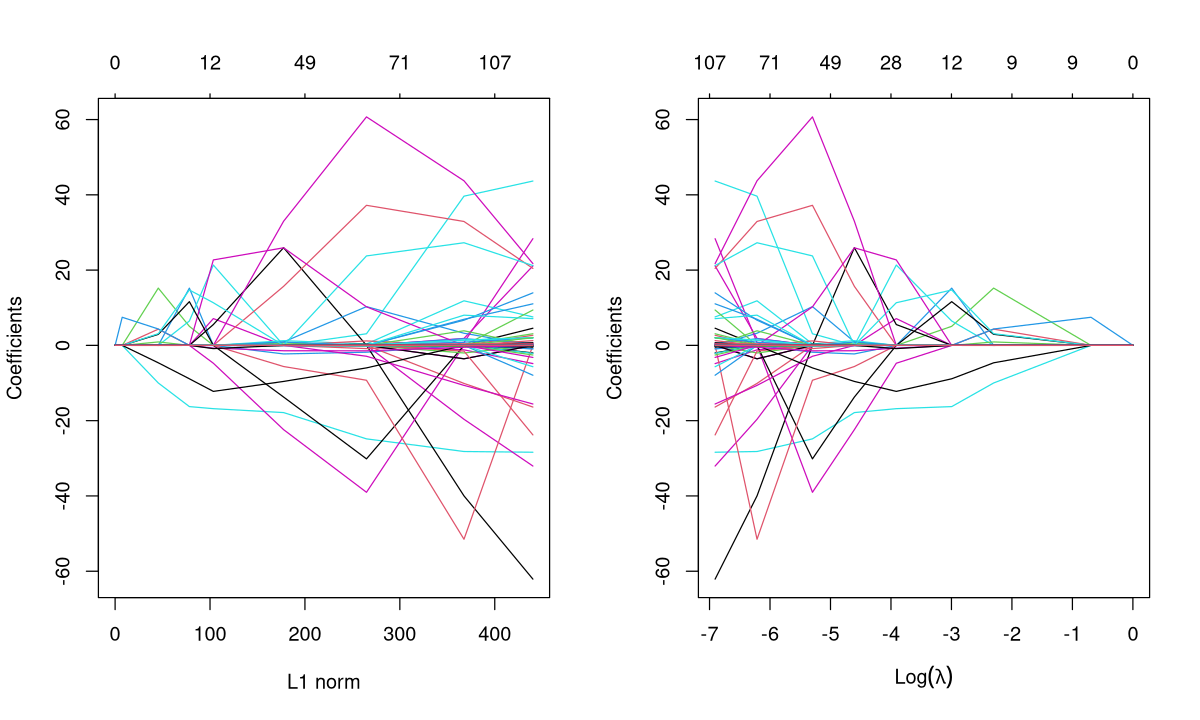

In [18]:
# Point de contrôle
X <- as.matrix(fa[, 5:1064])
lasso.mod <- glmnet(X, y, alpha = 1, family = "gaussian",
                    lambda = c(1, 0.5, 0.1, 0.05, 0.02, 0.01, 0.005, 0.002, 0.001))
perf <- function(mod) {
  c(k = length(coef(mod)) - 1, R2 = summary(mod)$r.squared, adjR2 = summary(mod)$adj.r.squared,
    SEP = sqrt(sum(resid(mod)^2) / mod$df.residual), AIC = AIC(mod))
}
res <- NULL
for (i in 1:length(lasso.mod$lambda)) {
  sel <- which(lasso.mod$beta[, i] != 0)
  if (length(sel) > 0) res <- rbind(res, c(lambda = lasso.mod$lambda[i], perf(lm(y ~ X[, sel]))))
}
par(mfrow = c(1, 2))
plot(lasso.mod, xvar = "norm", xlab = "L1 norm")
plot(lasso.mod, xvar = "lambda", sign.lambda = 1)
par(mfrow = c(1, 1))
kable(res, digits = 4)

## Étape 9 : modèle final, variables du Lasso (λ = 0.002) et outliers

**Énoncé**

1. Récupère dans `sel` les variables gardées par le Lasso pour **λ = 0.002**.
2. Construis un data.frame `data1` contenant `y` (première colonne, nommée `"y"`) et ces variables, puis ajuste `final0 <- lm(y ~ ., data = data1)`.
3. Trace la distance de Cook et identifie les observations dont la distance de Cook dépasse **4/n** (objet `outliers`).

In [19]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
sel <- which(lasso.mod$beta[, lasso.mod$lambda == 0.002] != 0)
length(sel)                                    # 71 points spectraux
data1 <- data.frame(y = y, X[, sel])
names(data1)[1] <- "y"
final0 <- lm(y ~ ., data = data1)              # "~ ." = toutes les autres colonnes de data1

par(mfrow = c(1, 1))
plot(final0, which = 4)
cook <- cooks.distance(final0)
outliers <- which(cook > 4 / length(y))
outliers
length(outliers)                               # 36 observations
```

(La ligne parasite `co` qui suivait `outliers` dans le script original du homework provoquait une erreur « objet 'co' introuvable » : elle est supprimée ici.)

</details>

**Questions d'interprétation**

1. Pourquoi utiliser un data.frame et la formule `y ~ .` plutôt que `lm(y ~ X[, sel])` ?
2. La résolution de la lactoferrine proposait un seuil de **1** pour la distance de Cook ; le homework utilise **4/n** (≈ 0.008). Quelle différence ? Que penses-tu du retrait de 36 observations ?

<details>
<summary><b>Voir la réponse</b></summary>

1. Avec un data.frame, chaque variable garde **son propre nom** (X12, X13…) dans le modèle : c'est indispensable pour que `stepAIC` puisse retirer les variables **une par une** et pour pouvoir ensuite **prédire** de nouveaux échantillons avec `predict(modele, newdata = ...)`. Avec `X[, sel]`, la matrice est un seul terme de la formule.
2. Une distance de Cook > 1 signale une observation **très** influente (règle conservatrice) ; 4/n est une règle **beaucoup plus sévère** qui signale toutes les observations nettement plus influentes que la moyenne. Retirer 36 échantillons sur 485 (7 %) est **important** : le cours rappelle qu'une valeur extrême n'est pas forcément un outlier et qu'il faut **vérifier l'origine** des échantillons signalés avant de les supprimer. Le R² obtenu sans eux sera mécaniquement meilleur, mais le modèle risque d'être moins bon sur des échantillons « atypiques » rencontrés en routine.

</details>

n_variables_lasso        n_outliers 
               71                36

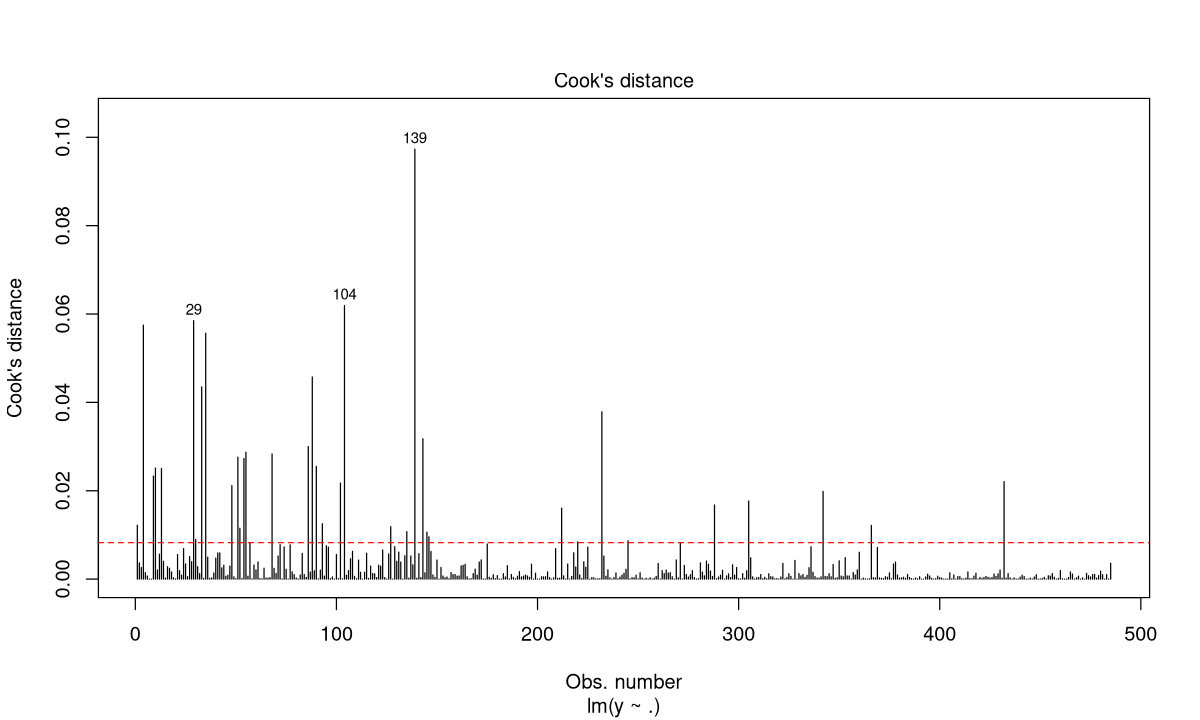

In [20]:
# Point de contrôle
sel <- which(lasso.mod$beta[, lasso.mod$lambda == 0.002] != 0)
data1 <- data.frame(y = y, X[, sel])
names(data1)[1] <- "y"
final0 <- lm(y ~ ., data = data1)
cook <- cooks.distance(final0)
outliers <- which(cook > 4 / length(y))
plot(final0, which = 4)
abline(h = 4 / length(y), col = "red", lty = 2)
c(n_variables_lasso = length(sel), n_outliers = length(outliers))

## Étape 10 : ajustement final sans les outliers + backward

**Énoncé**

1. Crée `data2` = `data1` sans les lignes `outliers`, et ajuste `final1 <- lm(y ~ ., data = data2)`.
2. Applique une sélection **backward** silencieuse (`trace = 0`) : objet `best`.
3. Fais l'analyse des résidus de `best` (4 graphes, Shapiro, Cook), affiche son résumé et ses performances avec `perf(best)`.

In [21]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
data2  <- data1[-outliers, ]                   # indices négatifs = on retire ces lignes
final1 <- lm(y ~ ., data = data2)
best   <- stepAIC(final1, direction = "backward", trace = 0)

par(mfrow = c(2, 2))
plot(best)
pander_md(shapiro.test(resid(best)))
par(mfrow = c(1, 1))
plot(best, which = 4)
pander_md(summary(best))
perf(best)
```

Résultats attendus : **43 variables** retenues (sur 71), n = 449, **R² ≈ 0.9956**, R² ajusté ≈ 0.9951, **SEP ≈ 0.058 g/dl**, résidus normaux (Shapiro p ≈ 0.57).

</details>

**Questions d'interprétation**

1. Compare le SEP final (≈ 0.058 g/dl) à celui de la régression univariée (≈ 0.21 g/dl). Peut-on affirmer que le modèle final prédira 4 fois mieux de nouveaux échantillons ?
2. Que manque-t-il à cette démarche pour valider l'équation ?

<details>
<summary><b>Voir la réponse</b></summary>

1. **Non.** Toutes ces performances sont des performances de **calibration** : elles sont mesurées sur les données qui ont servi à choisir les variables (Lasso, backward) **et** à estimer les coefficients, après avoir retiré les observations gênantes. Avec 43 variables, le risque de **surajustement** existe ; la performance sur de nouveaux échantillons sera moins bonne.
2. Une **validation sur un jeu de données indépendant** (dernière étape du processus KDD) : calculer l'erreur de prédiction (RMSEP) sur des échantillons qui n'ont servi ni à la sélection ni à la calibration. C'est l'objet du **module 2** (validation croisée, jeu de test).

</details>

k         R2      adjR2        SEP        AIC 
   43.0000     0.9956     0.9951     0.0577 -1243.9718


	Shapiro-Wilk normality test

data:  resid(best)
W = 0.99694, p-value = 0.5651


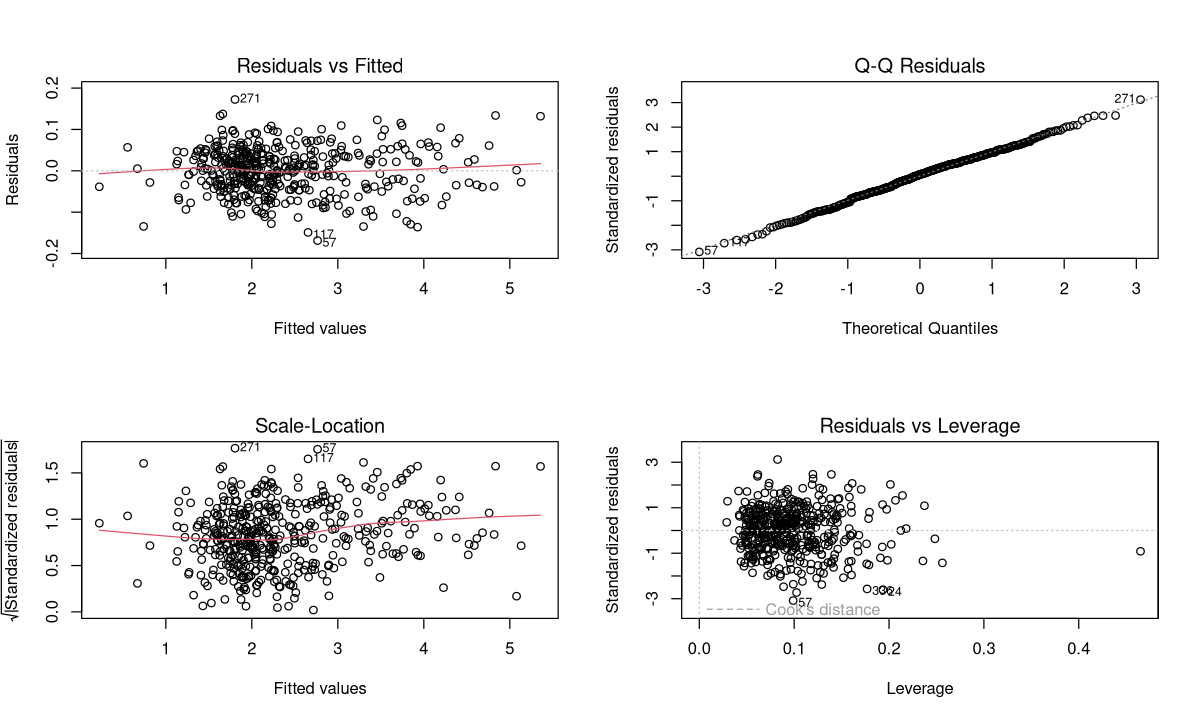

In [22]:
# Point de contrôle
data2  <- data1[-outliers, ]
final1 <- lm(y ~ ., data = data2)
best   <- stepAIC(final1, direction = "backward", trace = 0)
par(mfrow = c(2, 2))
plot(best)
par(mfrow = c(1, 1))
round(perf(best), 4)
shapiro.test(resid(best))

### Bilan des modèles du TP

In [23]:
bilan <- rbind(
  "1. univariée (X213)"             = perf(reg1),
  "2. multivariée 10 features"      = perf(reg2),
  "3. backward sur 10 features"     = perf(backward),
  "4. lm sur Lasso λ=0.002 (71 var)" = perf(final0),
  "5. final : sans outliers + backward" = perf(best)
)
kable(bilan, digits = 4)



|                                    |  k|     R2|  adjR2|    SEP|        AIC|
|:-----------------------------------|--:|------:|------:|------:|----------:|
|1. univariée (X213)                 |  1| 0.9392| 0.9391| 0.2116|  -125.9644|
|2. multivariée 10 features          | 10| 0.9546| 0.9536| 0.1847|  -249.0762|
|3. backward sur 10 features         |  9| 0.9546| 0.9537| 0.1845|  -251.0583|
|4. lm sur Lasso λ=0.002 (71 var)    | 71| 0.9921| 0.9907| 0.0827|  -973.5354|
|5. final : sans outliers + backward | 43| 0.9956| 0.9951| 0.0577| -1243.9718|

Le modèle 5 est ajusté sur **449** observations (outliers retirés) et les autres sur 485 : les AIC ne sont **pas comparables** entre modèles ajustés sur des données différentes.

## Étape 11 : sauvegarder la meilleure équation

**Énoncé**

1. Sauvegarde l'objet `best` avec `save()` dans le fichier `best_model_SAT.RData` **du dossier courant (Cours/)**, pour ne pas écraser le fichier original `Homework1/best_model.RData`.
2. Supprime `best` de la session (`rm()`), puis recharge-le avec `load()`.
3. Utilise-le pour prédire la teneur en SAT des 5 premiers échantillons de `data1` et compare aux valeurs observées.

In [24]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
save(best, file = "best_model_SAT.RData")     # le homework utilisait file = "best_model.RData"
rm(best)
exists("best")                                # FALSE
load("best_model_SAT.RData")                  # recrée l'objet best dans la session
exists("best")                                # TRUE

pred <- predict(best, newdata = data1[1:5, ])
cbind(observe = data1$y[1:5], predit = round(pred, 3))
```

Remarque : les échantillons 1 et 4 font partie des 36 outliers retirés à l'étape 9 ; l'échantillon 4 est d'ailleurs le moins bien prédit (4.39 observé contre ≈ 3.95 prédit).

`save()` enregistre un ou plusieurs objets R **avec leur nom** ; `load()` les recrée tels quels. Pour prédire avec `predict(best, newdata = ...)`, `newdata` doit contenir des colonnes **portant les mêmes noms** que les variables du modèle (X13, X48…) : c'est l'intérêt d'avoir construit le modèle sur un data.frame.

</details>

In [25]:
# Point de contrôle
save(best, file = "best_model_SAT.RData")
rm(best)
load("best_model_SAT.RData")
pred <- predict(best, newdata = data1[1:5, ])
cbind(observe = data1$y[1:5], predit = round(pred, 3))

,observe,predit
1,2.776,2.926
2,4.199,4.261
3,4.583,4.617
4,4.394,3.949
5,2.403,2.417


## Bonus : généraliser la démarche à MONO et POLY

Le fichier contient aussi les acides gras **mono-insaturés (MONO, colonne 3)** et **poly-insaturés (POLY, colonne 4)**.

### Exercice bonus

Écris une fonction `analyse_trait(col)` qui, pour la colonne `col` de `fa` :

1. trouve le point spectral le plus corrélé et renvoie le R² de la régression univariée ;
2. ajuste un Lasso sur le spectre entier avec la séquence de λ **automatique** de glmnet ;
3. pour le plus grand λ gardant au moins 20 variables, ajuste un `lm` sur ces variables et renvoie `perf()`.

Applique-la à SAT (colonne 2), MONO (3) et POLY (4). Quel acide gras est le mieux prédit ? Pourquoi, à ton avis ?

In [26]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
analyse_trait <- function(col) {
  yt   <- fa[, col]
  r    <- cor(fa[, 5:1064], yt)[, 1]
  best_point <- names(which.max(abs(r)))
  R2_uni <- summary(lm(yt ~ fa[, best_point]))$r.squared
  las  <- glmnet(X, yt, alpha = 1)
  i20  <- min(which(las$df >= 20))               # plus grand λ avec >= 20 variables
  s20  <- which(las$beta[, i20] != 0)
  c(point_le_plus_correle = best_point, R2_univarie = round(R2_uni, 3),
    lambda = signif(las$lambda[i20], 3), round(perf(lm(yt ~ X[, s20])), 3))
}
sapply(c(SAT = 2, MONO = 3, POLY = 4), analyse_trait)
```

Résultats attendus : **SAT** est le mieux prédit (R² univarié ≈ 0.94, R² ≈ 0.97 avec ~20 variables), puis **MONO** (≈ 0.74 → 0.82), puis **POLY** (≈ 0.62 → 0.71). POLY est présent en très faible quantité (≈ 0.17 g/dl contre ≈ 2.4 g/dl pour SAT) : comme pour la lactoferrine, plus un composé est **mineur**, plus son signal infrarouge est faible et plus la prédiction est difficile.

Le SEP de POLY (≈ 0.03 g/dl) est le plus petit… parce que POLY varie peu ! Pour comparer des variables d'échelles différentes, compare plutôt le **R²** ou le rapport **SEP / écart-type de y**. Écrire une **fonction** permet de répéter exactement la même démarche sur plusieurs variables : c'est la **généralisation** du script.

</details>

---

# PARTIE B : Correction officielle, la démarche de la professeure

Cette partie suit pas à pas la **correction officielle du homework** rédigée par H. Soyeurt : `Homework1/fatty_acids_20201006.Rmd` (son rendu Word est `fatty_acids_20201006.docx`). La démarche diffère de celle de la partie A : au lieu de partir des 10 points les plus corrélés, la professeure **nettoie d'abord le spectre** (points bruités), puis **réduit la colinéarité** en choisissant un point par région spectrale, et utilise enfin le Lasso comme **outil de sélection**.

> Si tu commences directement ici, exécute d'abord la cellule **0. Préparation** (packages + `pander_md`). On charge en plus `corrplot`.
>
> Les noms d'objets sont ceux du `.Rmd` (`fattyacid`, `spectra`, `spectra2`…). Attention : `y` y redevient un **vecteur** (et non une matrice 1 colonne) ; cela ne change rien aux calculs.

In [27]:
suppressPackageStartupMessages(library(corrplot))   # graphes de matrices de corrélation

## B1. Lecture et statistiques descriptives de SAT

**Énoncé**

1. Lis `../Homework1/fatty_acids.csv` dans un objet `fattyacid` et affiche la structure des **10 premières colonnes** seulement (argument `list.len` de `str()`).
2. Crée le vecteur `y` (SAT, colonne 2), affiche `descr(y)` et l'histogramme (20 classes).

In [28]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
fattyacid <- read.table(file = "../Homework1/fatty_acids.csv", sep = ";", header = TRUE)  # header = TRUE : 1re ligne = titres
str(fattyacid, list.len = 10)      # n'affiche que les 10 premières colonnes
y <- fattyacid[, 2]                # SAT, MONO et POLY sont en colonnes 2, 3 et 4
descr(y)
par(mfrow = c(1, 1))
hist(y, breaks = 20, col = "blue", xlab = "Saturated fatty acids", main = NULL)
```

La correction conclut : *« The distribution seems to be more or less normal »*. Elle garde donc SAT **sans transformation**, comme la partie A.

Petit piège du `.Rmd` : le texte écrit « *the matrix y has `nrow(y)` rows* », or `y <- fattyacid[, 2]` est un **vecteur** : `nrow(y)` renvoie `NULL`. Pour un vecteur, on utilise `length(y)` (485).

</details>

In [29]:
# Point de contrôle
fattyacid <- read.table(file = "../Homework1/fatty_acids.csv", sep = ";", header = TRUE)
y <- fattyacid[, 2]
length(y)    # 485
nrow(y)      # NULL : un vecteur n'a pas de lignes

[1] 485

NULL

## B2. Statistiques descriptives des features (le spectre)

La correction calcule les statistiques de **chaque point spectral** avec `descr()` appliqué au data.frame du spectre.

> **Piège signalé par la professeure** : *« the function descr() reorders the results in function of column names »*. `descr()` trie les variables **par ordre alphabétique** de leur nom. Or, alphabétiquement, `"X10"` vient avant `"X2"` ! Les statistiques ne seraient plus dans l'ordre du spectre. La solution : renommer les colonnes avec **le même nombre de chiffres** (`X0001` … `X1060`).

Démonstration du problème sur les 12 premiers points :

In [30]:
spectra <- data.frame(fattyacid[, 5:ncol(fattyacid)])   # le spectre seul (1060 colonnes)
rownames(descr(spectra[, 1:12], stats = "common", transpose = TRUE))   # ordre alphabétique !

[1] "X1"  "X10" "X11" "X12" "X2"  "X3"  "X4"  "X5"  "X6"  "X7"  "X8"  "X9"

**Énoncé**

1. Renomme les colonnes de `spectra` en `X0001`, …, `X0009`, `X0010`, …, `X1060`. La correction utilise `paste0()` par tranche (`"X000"` pour 1 à 9, `"X00"` pour 10 à 99, …). Généralisation plus compacte : `sprintf("X%04d", 1:1060)` (`%04d` = entier écrit sur 4 chiffres complété par des zéros).
2. Calcule `stat <- descr(spectra, stats = c("common"), transpose = TRUE)` (`"common"` = moyenne, écart-type, min, médiane, max + effectifs).
3. Trace le spectre **moyen** (noir), **min** (bleu) et **max** (vert) avec une légende.

In [31]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
# Version de la correction
colspectra <- rbind(as.matrix(paste0("X000", 1:09)), as.matrix(paste0("X00", 10:99)),
                    as.matrix(paste0("X0", 100:999)), as.matrix(paste0("X", 1000:1060)))
names(spectra) <- colspectra
# Version compacte équivalente
all(colspectra == sprintf("X%04d", 1:1060))        # TRUE

stat <- descr(spectra, stats = c("common"), transpose = TRUE)
head(rownames(stat))                               # X0001, X0002, ... : bon ordre

par(mfrow = c(1, 1))
plot(stat$Mean, type = "l", ylab = "Spectral absorption", xlab = "Spectral data point", ylim = c(-1, 2))
lines(stat$Min, type = "l", col = "blue")
lines(stat$Max, type = "l", col = "green")
legend(x = 700, y = 2, legend = c("Mean", "Min", "Max"), col = c("black", "blue", "green"), lty = c(1, 1, 1), cex = 1)
```

</details>

**Question** : que t'apprend ce graphe ?

<details>
<summary><b>Voir la réponse</b></summary>

Certains points spectraux ont une **étendue de variation très grande** par rapport aux autres (min et max très éloignés de la moyenne, surtout autour des points 180-200 et 550-700). Comme le dit la correction, cela peut révéler des **régions bruitées** (zones d'absorption de l'eau par exemple, cf. « *some noisy regions* » dans les slides). D'où l'idée de regarder le coefficient de variation de chaque point.

</details>

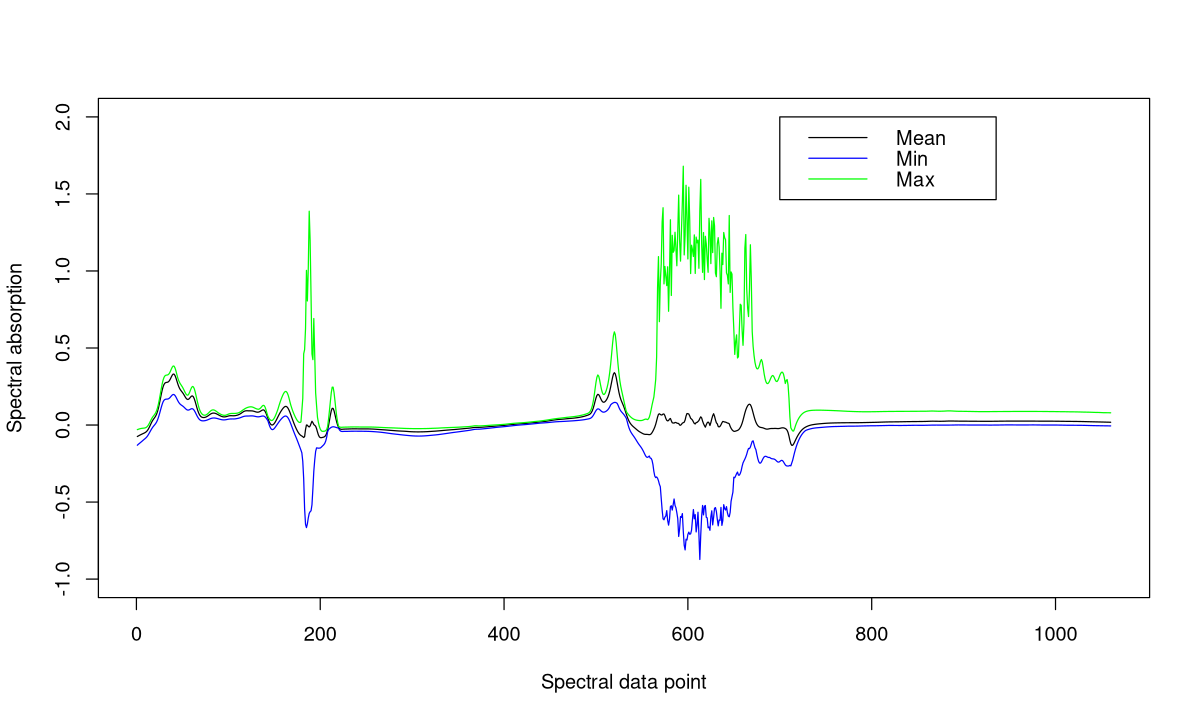

In [32]:
# Point de contrôle
colspectra <- sprintf("X%04d", 1:1060)
names(spectra) <- colspectra
stat <- descr(spectra, stats = c("common"), transpose = TRUE)
par(mfrow = c(1, 1))
plot(stat$Mean, type = "l", ylab = "Spectral absorption", xlab = "Spectral data point", ylim = c(-1, 2))
lines(stat$Min, type = "l", col = "blue")
lines(stat$Max, type = "l", col = "green")
legend(x = 700, y = 2, legend = c("Mean", "Min", "Max"), col = c("black", "blue", "green"), lty = 1)

## B3. Coefficient de variation par point et filtre des régions bruitées

**Énoncé**

1. Calcule le CV (en %) de chaque point spectral : `CV <- (100 / stat$Mean) * stat$Std.Dev`, et affiche son résumé.
2. Trace les CV (points bleus, `ylim = c(-100, 100)`).
3. Garde dans `spectra2` les points dont le CV est **≤ 50 %**. Combien en reste-t-il ?

In [33]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
CV <- (100 / stat$Mean) * stat$Std.Dev
pander_md(summary(CV))
plot(CV, ylim = c(-100, 100), type = "p", col = "blue", ylab = "Coefficient of variation", xlab = "Spectral data point")
spectra2 <- spectra[, CV <= 50]        # on garde les CV <= 50 %
ncol(spectra2)                         # 809 features
```

Le CV varie de ≈ −20 469 % à ≈ 433 750 % : des valeurs **trop extrêmes pour être réalistes**, qui suggèrent du bruit.

</details>

### Texte vs code : valeur absolue ou pas ?

Le texte de la correction dit : *« we can fix the **absolute value** of the coefficient of variation to 50 % »*, mais le code teste `CV <= 50` **sans** `abs()`. Or le CV est **négatif** dès que la moyenne de l'absorbance est négative (336 points ici) : avec `CV <= 50`, **tous** ces points sont gardés, même celui dont le CV vaut −20 469 % ! Comparons :

In [34]:
CV <- (100 / stat$Mean) * stat$Std.Dev           # CV en % de chaque point (cf. solution)
c(CV_inf_50_code_Rmd   = sum(CV <= 50),          # ce que fait le code : 809
  absCV_inf_50_texte    = sum(abs(CV) <= 50),     # ce que dit le texte : 687
  CV_negatifs           = sum(CV < 0))

# Les 14 points qui seront retenus plus loin (B5) : lesquels seraient éliminés avec abs() ?
sel14 <- c("X0001","X0015","X0063","X0070","X0200","X0219","X0299","X0322","X0498","X0507","X0511","X0528","X0539","X0553")
data.frame(CV = round(CV[match(sel14, colspectra)], 1), garde_avec_abs = abs(CV[match(sel14, colspectra)]) <= 50,
           row.names = sel14)

CV_inf_50_code_Rmd absCV_inf_50_texte        CV_negatifs 
               809                687                336

,CV,garde_avec_abs
,<dbl>,<lgl>
X0001,-23.1,TRUE
X0015,-536.6,FALSE
X0063,11.9,TRUE
X0070,14.4,TRUE
X0200,-24.2,TRUE
X0219,-244.8,FALSE
X0299,-18.1,TRUE
X0322,-18.3,TRUE
X0498,14.1,TRUE


**Que faut-il en penser ?**

- avec la valeur absolue (le texte), il resterait **687** features et non 809, et 4 des 14 points finalement retenus (X0015, X0219, X0539, X0553) auraient été éliminés ;
- **mais** un |CV| énorme n'est pas forcément du bruit : le CV = s / moyenne **explose quand la moyenne est proche de 0**. Or des absorbances moyennes proches de 0 (voire négatives) sont fréquentes dans un spectre. X0539 (CV ≈ −1293 %) est pourtant très corrélé à SAT (|r| > 0.9) !
- **leçon** : le CV n'est un bon indicateur de bruit que pour des variables **strictement positives** et loin de 0 (cf. partie 1). Il est plus sûr de juger le bruit sur l'écart-type, sur la répétabilité des mesures ou sur la connaissance des régions spectrales (régions de l'eau). Dans la suite, on **suit le code de la correction** (`CV <= 50`, 809 features) pour retrouver ses résultats.

In [35]:
# Point de contrôle
CV <- (100 / stat$Mean) * stat$Std.Dev
spectra2 <- spectra[, CV <= 50]
ncol(spectra2)

[1] 809

## B4. Colinéarité entre features et corrélation avec SAT

**Énoncé**

1. Calcule la matrice de corrélation des 809 features (`corspectra`), transforme-la en vecteur et trace son histogramme.
2. Calcule `correlationSAT <- abs(cor(y, spectra2))` et trace-le (ligne rouge).
3. Combien de features ont une corrélation absolue avec SAT **> 0.5** ? **> 0.9** ?
4. Garde dans `spectra3` les features avec |r| > 0.9, trace l'histogramme de leurs corrélations mutuelles et la carte de chaleur `corrplot(abs(cor(spectra3)), method = "color", tl.pos = "n")`.

In [36]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
corspectra  <- cor(spectra2)                  # 809 x 809
corspectra2 <- as.vector(corspectra)          # la matrice "mise à plat" en un vecteur
hist(corspectra2, main = NULL, xlab = "Spectral correlation values", col = "blue")

correlationSAT <- abs(cor(y, spectra2))       # matrice 1 x 809
par(mfrow = c(1, 1))
plot(x = c(1:length(correlationSAT)), y = correlationSAT, type = "l", col = "red",
     ylab = "Absolute correlation values", xlab = "x index")
c(sup_0.5 = sum(correlationSAT > 0.5), sup_0.9 = sum(correlationSAT > 0.9))   # 553 et 104

spectra3 <- spectra2[, correlationSAT > 0.90]
correlation <- as.vector(abs(cor(spectra3)))
hist(correlation, main = NULL)
corrplot(abs(cor(spectra3)), method = "color", tl.pos = "n")   # tl.pos = "n" : pas d'étiquettes
```

</details>

**Questions**

1. Que montre l'histogramme des corrélations entre features ?
2. Quel est le critère idéal de choix des features énoncé par la correction ?

<details>
<summary><b>Voir la réponse</b></summary>

1. Beaucoup de corrélations sont proches de ±1 : de nombreuses features **partagent la même information** → risque de **colinéarité** dans une régression multivariée.
2. Les features les plus intéressantes sont celles qui ont **la plus forte corrélation avec le caractère étudié** et **la plus faible corrélation entre elles** (pour limiter l'information redondante). Le seuil |r| > 0.9 réalise le premier critère (104 features) ; la carte de chaleur montre que le second n'est pas encore atteint : les features **proches** dans le spectre restent très corrélées (blocs foncés).

</details>

sup_0.5 sup_0.9 
    553     104

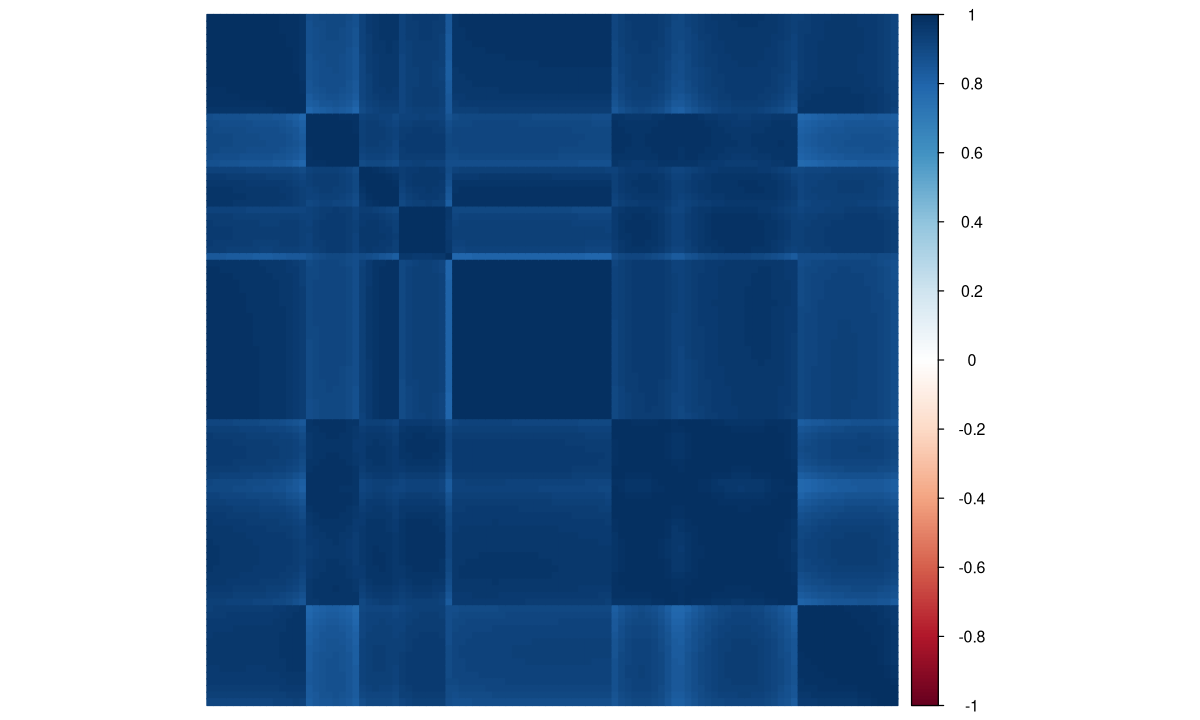

In [37]:
# Point de contrôle
correlationSAT <- abs(cor(y, spectra2))
spectra3 <- spectra2[, correlationSAT > 0.90]
c(sup_0.5 = sum(correlationSAT > 0.5), sup_0.9 = ncol(spectra3))
corrplot(abs(cor(spectra3)), method = "color", tl.pos = "n")

## B5. Une feature par région spectrale

Les 104 features retenues se regroupent en **régions** de points contigus. La correction liste 7 régions : 1-15, 63-70, 200-219, 299-322, 498-507, 511-528 et 539-553. Comme les features proches sont les plus corrélées, *« the best is to chose one feature per region »* : elle prend la **première et la dernière feature de chaque région**, soit **14 features** (objet `spectra4`).

**Énoncé**

1. Affiche les noms des colonnes de `spectra3`.
2. *Généralisation* : retrouve les régions **automatiquement**. Extrais les numéros des points (`as.integer(sub("X", "", names(spectra3)))`), calcule les écarts entre numéros successifs avec `diff()`, et coupe une nouvelle région quand l'écart est > 1. Que se passe-t-il ? Et avec un écart > 5 ?
3. Crée `spectra4` avec les 14 features de la correction et trace l'histogramme de leurs corrélations absolues.

In [38]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
colspectra3 <- names(spectra3)
colspectra3

regions <- function(noms, ecart_max = 1) {
  idx   <- as.integer(sub("X", "", noms))           # "X0213" -> 213
  coupe <- which(diff(idx) > ecart_max)             # positions où un "trou" commence
  data.frame(debut = idx[c(1, coupe + 1)], fin = idx[c(coupe, length(idx))])
}
regions(colspectra3, ecart_max = 1)   # 9 régions : 200-219 est coupée en 200-205, 211-217 et 219
regions(colspectra3, ecart_max = 5)   # 7 régions : celles de la correction

spectra4 <- spectra3[, c("X0001","X0015","X0063","X0070","X0200","X0219","X0299","X0322",
                         "X0498","X0507","X0511","X0528","X0539","X0553")]
hist(abs(cor(spectra4)), main = NULL, xlab = "Absolute correlation value")
```

La région « 200-219 » de la correction contient deux petits trous (206-210 et 218) : la professeure les a considérés comme une seule région. Un critère automatique doit donc tolérer de petits écarts.

</details>

[1] 485  14

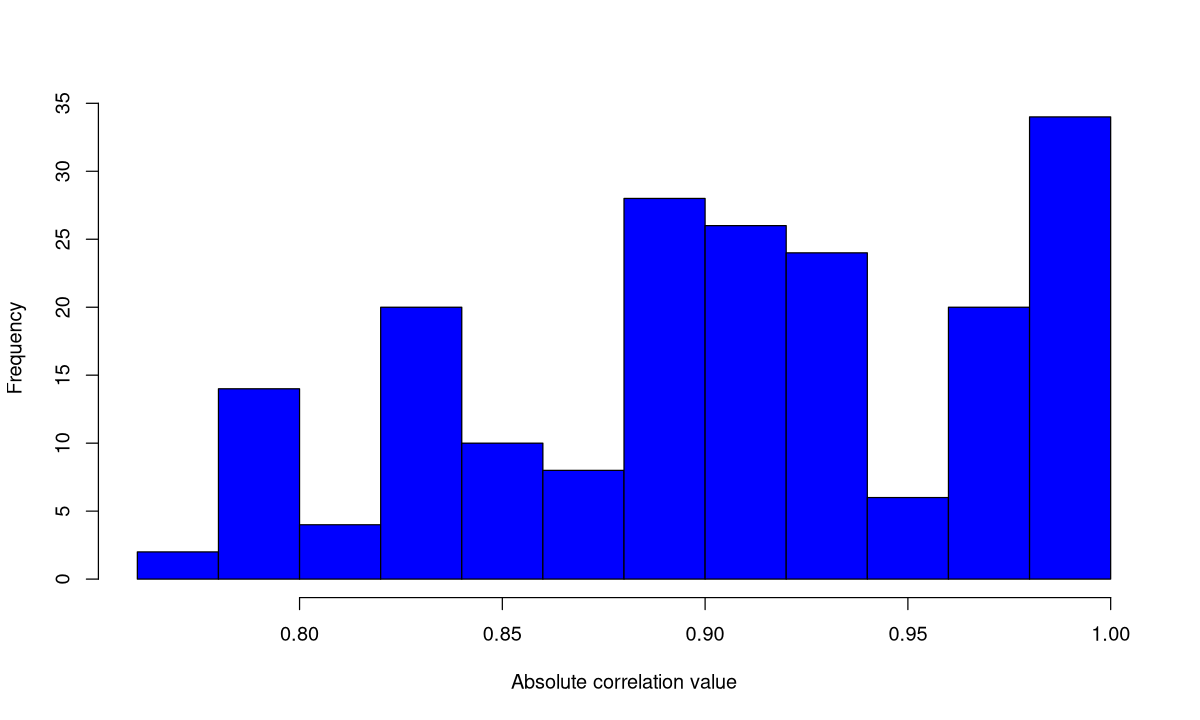

In [39]:
# Point de contrôle
spectra4 <- spectra3[, c("X0001","X0015","X0063","X0070","X0200","X0219","X0299","X0322",
                         "X0498","X0507","X0511","X0528","X0539","X0553")]
dim(spectra4)
hist(abs(cor(spectra4)), main = NULL, xlab = "Absolute correlation value", col = "blue")

## B6. Régression multivariée sur 14 puis 12 features

**Énoncé**

1. Ajuste `regSAT <- lm(y ~ as.matrix(spectra4))` et affiche le résumé. Quelles features ne sont pas significatives au seuil de 5 % ?
2. La correction retire **X0299 et X0219** : ajuste `regSAT2` sur les 12 features restantes (`spectra5`) et compare.
3. Fais l'analyse des résidus de `regSAT2` (4 graphes, Shapiro, Cook).

In [40]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
regSAT <- lm(y ~ as.matrix(spectra4))
pander_md(summary(regSAT))

spectra5 <- spectra3[, c("X0001","X0015","X0063","X0070","X0200","X0322","X0498","X0507",
                         "X0511","X0528","X0539","X0553")]
regSAT2 <- lm(y ~ as.matrix(spectra5))
pander_md(summary(regSAT2))

par(mfrow = c(2, 2))
plot(regSAT2)
pander_md(shapiro.test(resid(regSAT2)))
par(mfrow = c(1, 1))
plot(regSAT2, which = 4)
```

| Modèle | features | R² | R² ajusté | SEP (g/dl) |
|---|---|---|---|---|
| regSAT | 14 | 0.9665 | 0.9655 | 0.159 |
| regSAT2 | 12 | 0.9665 | 0.9656 | 0.159 |

Shapiro sur regSAT2 : W = 0.994, **p = 0.057 > 0.05** → normalité acceptée (de justesse).

</details>

**Questions**

1. La correction dit que « *2 features did not seem to be informative* ». Vérifie toutes les p-valeurs de `regSAT` : combien dépassent 5 % ?
2. Après retrait, la correction affirme « *All variables are now significant* ». Est-ce exact ?
3. Pourquoi le R² ne baisse-t-il pas quand on retire X0219 et X0299 ?

<details>
<summary><b>Voir la réponse</b></summary>

1. **Quatre** p-valeurs dépassent 0.05 : X0219 (p ≈ 0.57) et X0299 (p ≈ 0.93), clairement non informatives, mais aussi X0070 (p ≈ 0.083) et X0200 (p ≈ 0.079), « limites ». La correction n'a retiré que les deux franchement non significatives.
2. **Pas tout à fait** : dans `regSAT2`, X0070 et X0200 restent à p ≈ 0.08 (significatives à 10 % seulement). L'affirmation est vraie au seuil de 10 % (seuil que le syllabus autorise pour la stepwise : « *P-value less than 5 or 10 % depending on the desired threshold* »).
3. X0219 et X0299 sont dans les mêmes régions que X0200 et X0322, avec lesquelles elles sont fortement corrélées : leur information est **déjà apportée** par les autres features. Le modèle est **plus parcimonieux** pour la même performance, et le R² ajusté augmente légèrement (0.9655 → 0.9656).

</details>

(Intercept) as.matrix(spectra4)X0001 as.matrix(spectra4)X0015 
                   0.000                    0.000                    0.000 
as.matrix(spectra4)X0063 as.matrix(spectra4)X0070 as.matrix(spectra4)X0200 
                   0.000                    0.083                    0.079 
as.matrix(spectra4)X0219 as.matrix(spectra4)X0299 as.matrix(spectra4)X0322 
                   0.568                    0.928                    0.000 
as.matrix(spectra4)X0498 as.matrix(spectra4)X0507 as.matrix(spectra4)X0511 
                   0.000                    0.000                    0.000 
as.matrix(spectra4)X0528 as.matrix(spectra4)X0539 as.matrix(spectra4)X0553 
                   0.000                    0.000                    0.000

R2      adjR2        SEP  shapiro_p 
0.96648043 0.96562824 0.15899897 0.05670074

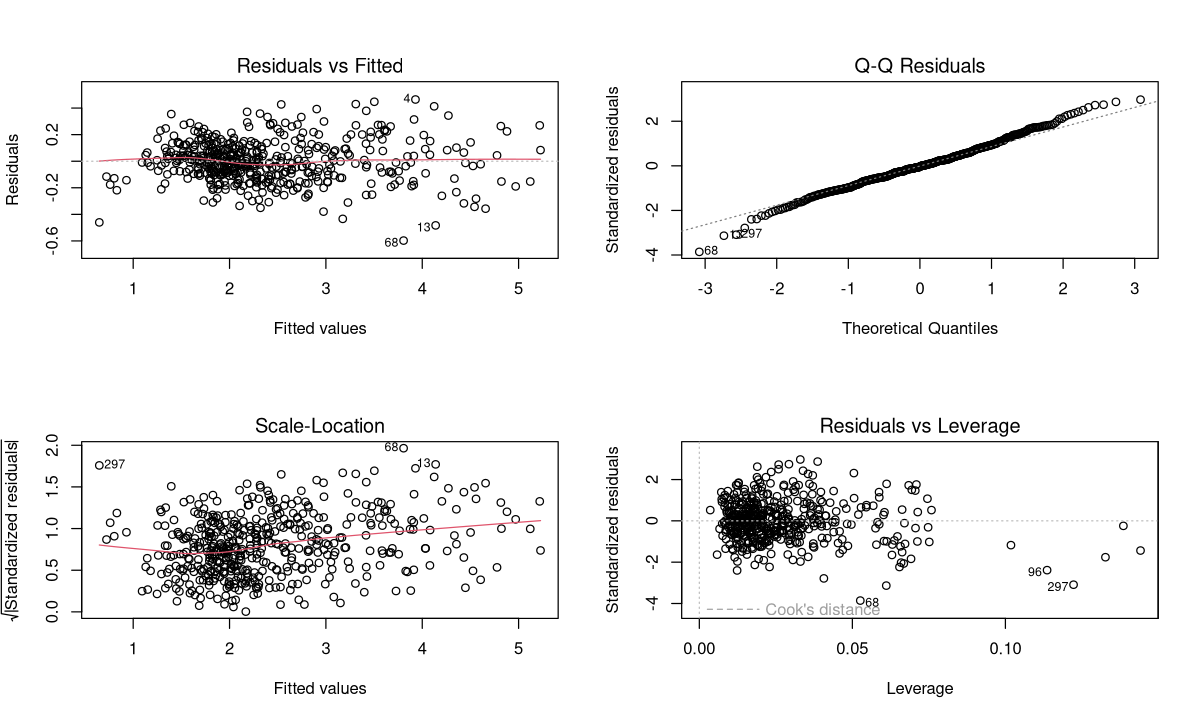

In [41]:
# Point de contrôle
regSAT  <- lm(y ~ as.matrix(spectra4))
spectra5 <- spectra3[, c("X0001","X0015","X0063","X0070","X0200","X0322","X0498","X0507",
                         "X0511","X0528","X0539","X0553")]
regSAT2 <- lm(y ~ as.matrix(spectra5))
round(summary(regSAT)$coefficients[, 4], 3)       # p-valeurs de regSAT
par(mfrow = c(2, 2)); plot(regSAT2); par(mfrow = c(1, 1))
c(R2 = summary(regSAT2)$r.squared, adjR2 = summary(regSAT2)$adj.r.squared,
  SEP = summary(regSAT2)$sigma, shapiro_p = shapiro.test(resid(regSAT2))$p.value)

## B7. Lasso sur les features corrélées à plus de 0.6

Pour aller plus loin, la correction utilise le Lasso comme outil de sélection. Elle fixe une limite : au plus **n − 1 = 484 features** (pour que la régression `lm` finale reste estimable). Avec le seuil |r| > 0.6, il reste **406 features** (`spectra6`).

**Énoncé**

1. Crée `spectra6`, puis ajuste le Lasso exactement comme la correction :
   `lasso.mod <- glmnet(as.matrix(spectra6), y, alpha = 1, lambda = c(5, 2, 1, 0.05, 0.25, 0.1, 0.01, 0.001, 0.0001), family = "gaussian")`
2. Trace les chemins (`xvar = "norm"` et `xvar = "lambda"`), puis le **nombre de variables sélectionnées en fonction de λ** (`lasso.mod$df` vs `lasso.mod$lambda`).
3. Affiche le tableau λ / nombre de variables / `dev.ratio`.
4. Compare `lasso.mod$lambda` à la grille que tu as donnée. Qu'en déduis-tu ?

In [42]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
spectra6 <- spectra2[, correlationSAT > 0.60]
ncol(spectra6)                                   # 406
set.seed(1001)
lasso.mod <- glmnet(as.matrix(spectra6), y, alpha = 1,
                    lambda = c(5, 2, 1, 0.05, 0.25, 0.1, 0.01, 0.001, 0.0001), family = "gaussian")
par(mfrow = c(1, 2))
plot(lasso.mod, xvar = "norm", xlab = "L1 norm")      # le .Rmd écrit "L2 norm" : c'est la norme L1 pour le Lasso
plot(lasso.mod, xvar = "lambda", sign.lambda = 1)
par(mfrow = c(1, 1))
plot(y = lasso.mod$df, x = lasso.mod$lambda, type = "o",
     ylab = "Number of selected variables by Lasso", xlab = "Lambda value")
text(x = lasso.mod$lambda[1:9], y = lasso.mod$df[1:9], labels = lasso.mod$df[1:9], pos = 4, col = "red")

finaltable <- data.frame(lasso.mod$lambda, lasso.mod$df, lasso.mod$dev.ratio)
names(finaltable) <- c("Lambda", "Number of selected variables", "dev.ratio")
kable(finaltable, digits = 4)
```

</details>

Warning message in regularize.values(x, y, ties, missing(ties), na.rm = na.rm):
“collapsing to unique 'x' values”


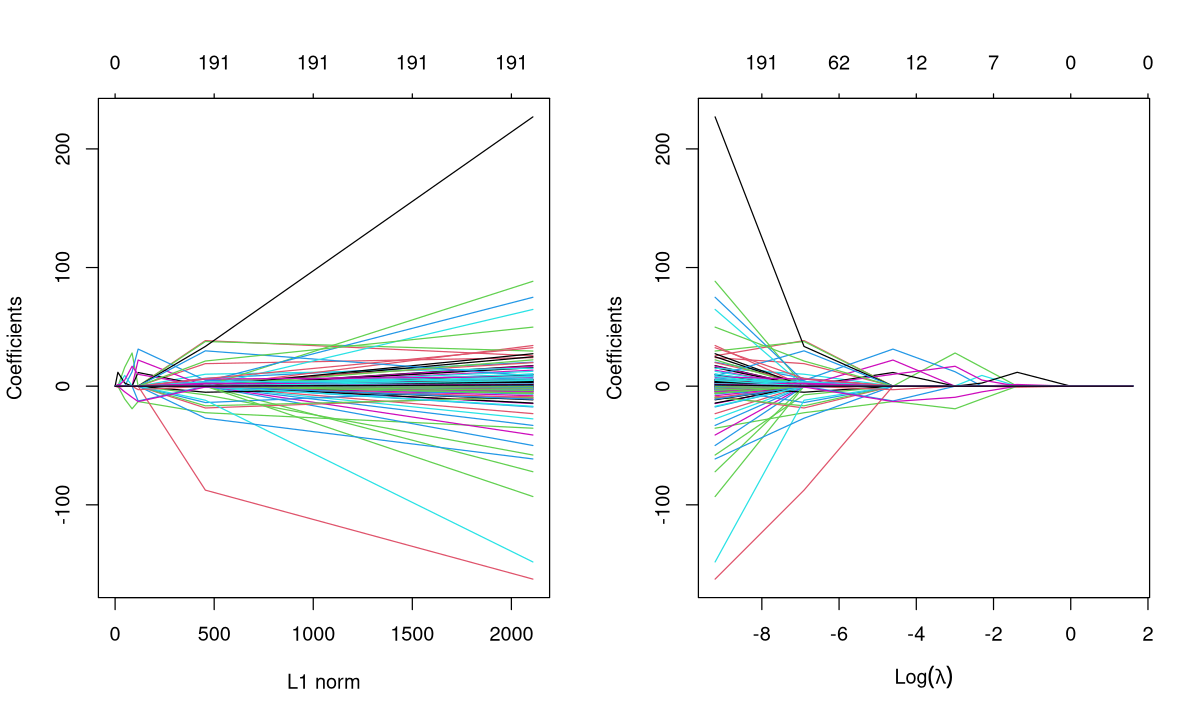



| colonne_beta| Lambda| n_variables| dev.ratio|
|------------:|------:|-----------:|---------:|
|            1| 5.0000|           0|    0.0000|
|            2| 2.0000|           0|    0.0000|
|            3| 1.0000|           0|    0.0000|
|            4| 0.2500|           3|    0.8545|
|            5| 0.1000|           7|    0.9345|
|            6| 0.0500|           7|    0.9505|
|            7| 0.0100|          12|    0.9595|
|            8| 0.0010|          62|    0.9803|
|            9| 0.0001|         191|    0.9909|

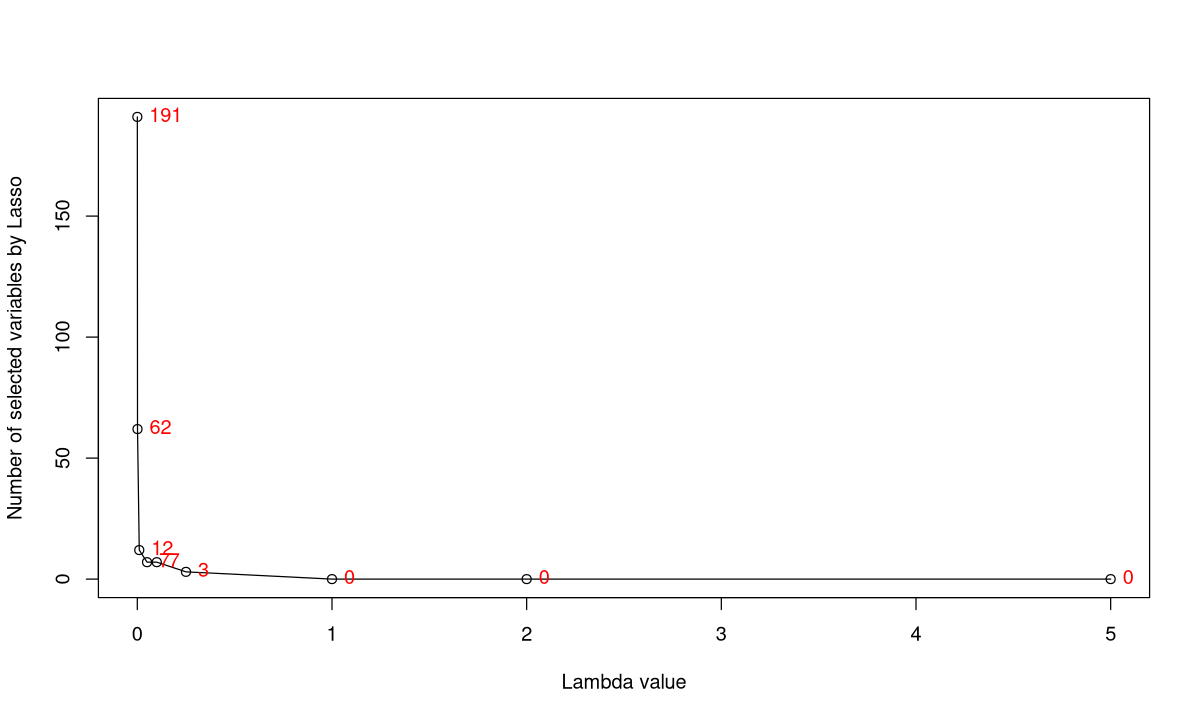

In [43]:
# Point de contrôle
spectra6 <- spectra2[, correlationSAT > 0.60]
set.seed(1001)
lasso.mod <- glmnet(as.matrix(spectra6), y, alpha = 1,
                    lambda = c(5, 2, 1, 0.05, 0.25, 0.1, 0.01, 0.001, 0.0001), family = "gaussian")
par(mfrow = c(1, 2))
plot(lasso.mod, xvar = "norm", xlab = "L1 norm")
plot(lasso.mod, xvar = "lambda", sign.lambda = 1)
par(mfrow = c(1, 1))
plot(y = lasso.mod$df, x = lasso.mod$lambda, type = "o",
     ylab = "Number of selected variables by Lasso", xlab = "Lambda value")
text(x = lasso.mod$lambda, y = lasso.mod$df, labels = lasso.mod$df, pos = 4, col = "red")
finaltable <- data.frame(colonne_beta = 1:9, Lambda = lasso.mod$lambda,
                         n_variables = lasso.mod$df, dev.ratio = round(lasso.mod$dev.ratio, 4))
kable(finaltable)

### Piège : la grille de λ n'est pas décroissante

La grille donnée est `c(5, 2, 1, 0.05, 0.25, 0.1, …)` : 0.05 est placé **avant** 0.25 et 0.1. **glmnet trie toujours les λ par ordre décroissant** ; dans l'objet, l'ordre est donc 5, 2, 1, **0.25, 0.1, 0.05**, 0.01, 0.001, 0.0001 (voir la colonne `Lambda` ci-dessus). La colonne `k` de `lasso.mod$beta` correspond au k-ième λ **trié**, pas au k-ième λ de la grille saisie.

Conséquence sur les légendes du `.Rmd` :

| Code du .Rmd | Légende (caption) | λ réel de la colonne | Correct ? |
|---|---|---|---|
| `lasso.mod$beta[, 4]` | « lambda = 0.25 » | 0.25 | oui (par chance) |
| `lasso.mod$beta[, 5]` | « lambda = 0.05 » | **0.1** | non |
| `lasso.mod$beta[, 6]` | « lambda = 0.01 » | **0.05** | non |

Vérification :

In [44]:
c(beta4 = lasso.mod$lambda[4], beta5 = lasso.mod$lambda[5], beta6 = lasso.mod$lambda[6])

# Ce que fait le .Rmd (indices de colonnes) ...
coefficient <- lasso.mod$beta[, 5]
names(coefficient[coefficient != 0])              # légende du .Rmd : "lambda = 0.05" -> faux, c'est λ = 0.1

# ... et la méthode robuste : sélectionner la colonne par la VALEUR de λ
coef_0.05 <- lasso.mod$beta[, lasso.mod$lambda == 0.05]
names(coef_0.05[coef_0.05 != 0])                   # vraiment λ = 0.05
# ou encore : coef(lasso.mod, s = 0.05)

beta4 beta5 beta6 
 0.25  0.10  0.05

[1] "X0012" "X0069" "X0211" "X0213" "X0219" "X0541" "X0542"

[1] "X0012" "X0069" "X0070" "X0209" "X0211" "X0219" "X0541"

Ici, λ = 0.1 et λ = 0.05 sélectionnent toutes deux **7 variables**, ce qui masque l'erreur ; mais ce ne sont pas exactement les mêmes variables ni les mêmes coefficients.

> **Bonnes pratiques avec glmnet** : donne toujours une grille **décroissante** (`sort(grille, decreasing = TRUE)`), et désigne un λ par sa **valeur** (`lasso.mod$lambda == 0.05`, `coef(mod, s = 0.05)`, `predict(mod, s = 0.05)`), jamais par un numéro de colonne. Autre remarque : `set.seed(1001)` n'a **aucun effet** sur `glmnet()`, dont l'algorithme est déterministe ; il serait utile avec `cv.glmnet()`, qui tire les blocs de validation au hasard.

### Exercice B7 : les variables sélectionnées

Affiche (avec `kable(t(...), digits = 3)`) les variables sélectionnées et leurs coefficients pour **λ = 0.25** et **λ = 0.01**, en désignant chaque λ par sa valeur.

In [45]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
for (l in c(0.25, 0.01)) {
  coefficient <- lasso.mod$beta[, lasso.mod$lambda == l]
  coefficient <- coefficient[coefficient != 0]
  print(kable(t(coefficient), digits = 3, caption = paste("Selected variables with lambda =", l)))
}
```

λ = 0.25 → 3 variables ; λ = 0.01 → 12 variables. Dans une boucle, `kable()` doit être entouré de `print()` pour s'afficher.

</details>

## B8. Régressions linéaires sur les variables retenues par le Lasso

La correction refait un `lm()` sur les variables retenues pour chacun des λ de la colonne 4 à la colonne 9 (`reg1` à `reg6`, six blocs de code quasi identiques), puis rassemble l'erreur standard résiduelle, le R² et le R² ajusté. Elle utilise une astuce : `as.matrix(summary(reg))[c(6, 8:9)]` extrait les éléments n° 6 (`sigma`), 8 (`r.squared`) et 9 (`adj.r.squared`) de l'objet résumé.

**Énoncé** : *généralise* ces six blocs en **une boucle** sur les λ qui sélectionnent au moins une variable, et construis un tableau λ / nombre de variables / SEP (sigma) / R² / R² ajusté.

In [46]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
reg_lasso <- list()
for (l in lasso.mod$lambda[lasso.mod$df > 0]) {
  coefficient <- lasso.mod$beta[, lasso.mod$lambda == l]
  variable    <- names(coefficient[coefficient != 0])
  spectra7    <- spectra6[, variable, drop = FALSE]      # drop = FALSE : reste un data.frame même avec 1 colonne
  reg_lasso[[as.character(l)]] <- lm(y ~ as.matrix(spectra7))
}
finaltable2 <- t(sapply(reg_lasso, function(m)
  c(n_variables = length(coef(m)) - 1, sigma = summary(m)$sigma,
    r.squared = summary(m)$r.squared, adj.r.squared = summary(m)$adj.r.squared)))
kable(finaltable2, digits = 4)
```

Avec une liste et une boucle, le code ne dépend plus de la position des colonnes et s'adapte à n'importe quelle grille de λ.

</details>

In [47]:
# Point de contrôle
reg_lasso <- list()
for (l in lasso.mod$lambda[lasso.mod$df > 0]) {
  coefficient <- lasso.mod$beta[, lasso.mod$lambda == l]
  variable    <- names(coefficient[coefficient != 0])
  reg_lasso[[as.character(l)]] <- lm(y ~ as.matrix(spectra6[, variable, drop = FALSE]))
}
finaltable2 <- t(sapply(reg_lasso, function(m)
  c(n_variables = length(coef(m)) - 1, sigma = summary(m)$sigma,
    r.squared = summary(m)$r.squared, adj.r.squared = summary(m)$adj.r.squared)))
kable(finaltable2, digits = 4)



|      | n_variables|  sigma| r.squared| adj.r.squared|
|:-----|-----------:|------:|---------:|-------------:|
|0.25  |           3| 0.2052|    0.9431|        0.9428|
|0.1   |           7| 0.1830|    0.9551|        0.9545|
|0.05  |           7| 0.1777|    0.9577|        0.9571|
|0.01  |          12| 0.1670|    0.9630|        0.9621|
|0.001 |          62| 0.0874|    0.9909|        0.9896|
|1e-04 |         191| 0.0594|    0.9971|        0.9952|

**Questions**

1. Quel λ choisirais-tu ? Compare avec `regSAT2`.
2. Que dit la conclusion de la correction ?

<details>
<summary><b>Voir la réponse</b></summary>

1. λ = 0.01 donne **12 variables** comme `regSAT2`, avec un R² un peu plus faible (0.963 contre 0.967) : le choix « une feature par région » de la professeure fait aussi bien que le Lasso à nombre de variables égal. Passer à 62 puis 191 variables (λ = 0.001 et 0.0001) augmente encore le R² ajusté, mais le risque de **surajustement** grandit avec le nombre de variables (191 variables pour 485 échantillons !). Sans jeu de validation, le choix raisonnable est un modèle **parcimonieux** de l'ordre de 12 variables.
2. Conclusion de la professeure : il est important de **sélectionner les variables les plus informatives** pour limiter la colinéarité et pour pouvoir construire un modèle avec peu de features quand le nombre d'échantillons est limité. On observe que le **R² ajusté tend à augmenter avec le nombre de features**. Sur base de la **calibration**, la prédiction de SAT est possible ; mais **avant d'utiliser une équation, il est crucial de la tester sur de nouveaux échantillons** : ce sera l'objet du **module 2**.

</details>

---

# PARTIE C : Script de la séance TP (2026)

Le fichier `Homework1/2026_AMV2_module1.R` est le script écrit par l'assistant pendant la séance de TP. Il propose une exploration **rapide** des mêmes données, avec quelques variantes de syntaxe utiles à connaître. On l'exécute ici bloc par bloc, en signalant les pièges.

> **Ce que montre ce script**
> - `read.csv()` : équivalent de `read.table(header = TRUE, sep = ",")` ; avec `sep = ";"` on lit le même fichier ;
> - tracer **un** spectre (une ligne du fichier) ;
> - calculer des statistiques **colonne par colonne** avec une boucle `for` et `descr()` ;
> - `glmnet` (Lasso et Ridge) sur le **spectre complet** avec λ = c(5, 2, 1, 0.5, 0.1, 0.01, 0.001) ;
> - extraire les coefficients non nuls ; régression simple `lm(y ~ X[, 213])`.

,y
Mean,2.4028371
Std.Dev,0.8576171
Min,0.1880000
Q1,1.8500000
Median,2.1510000
Q3,2.8110000
Max,5.4890000
MAD,0.6256572
IQR,0.9610000
CV,0.3569185


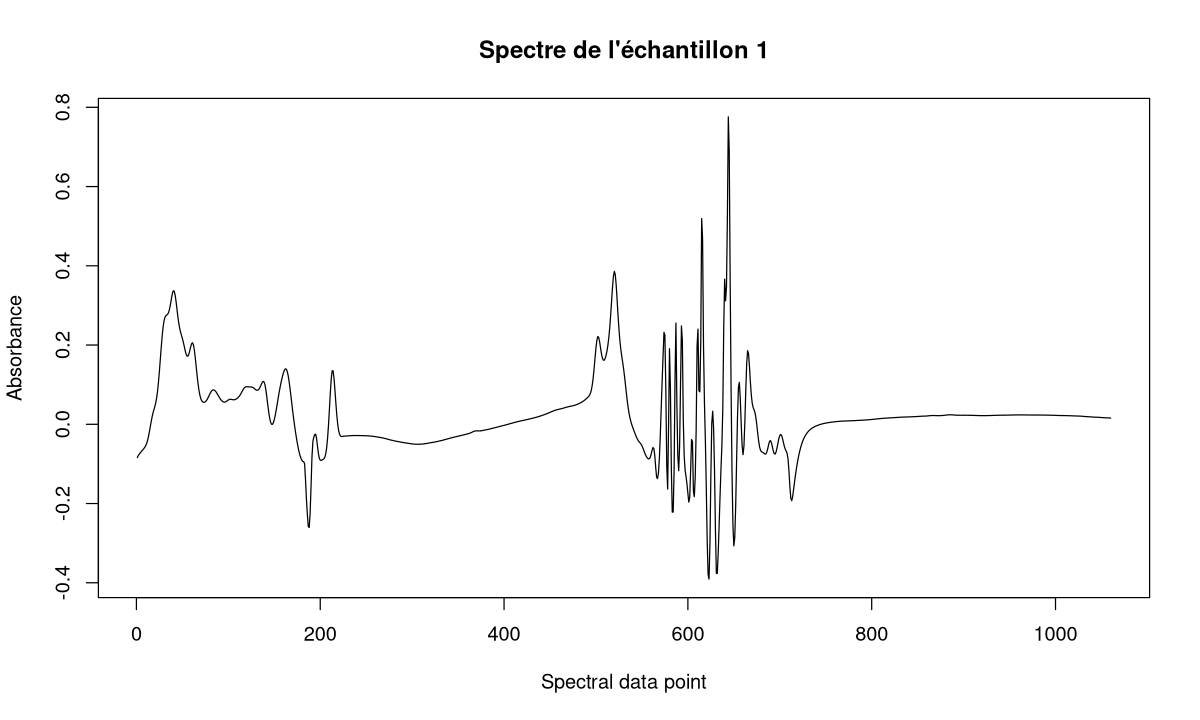

In [48]:
# setwd("C:/Users/.../TP1")     # chemin de l'assistant : inutile dans Jupyter
data <- read.csv("../Homework1/fatty_acids.csv", sep = ";", header = TRUE)

# Spectre du premier échantillon (ligne 1, colonnes 5 à 1064)
plot(x = c(1:1060), y = data[1, c(5:1064)], type = "l",
     xlab = "Spectral data point", ylab = "Absorbance", main = "Spectre de l'échantillon 1")

y <- as.numeric(data$SAT)
X <- data[, 5:1064]              # X est un data.frame (pas une matrice)
descr(y)

### C1. Statistiques point par point avec une boucle

Le script remplit 4 vecteurs (min, max, moyenne, CV) en appelant `descr()` sur chaque colonne. `descr()` sur une seule variable renvoie une matrice 1 colonne dont les lignes sont, dans l'ordre : Mean (1), Std.Dev (2), Min (3), Q1 (4), Median (5), Q3 (6), Max (7), MAD (8), IQR (9), **CV (10)**. D'où `tmp[3]` = min, `tmp[7]` = max, `tmp[1]` = moyenne, `tmp[10]` = CV.

> **Piège pratique** : écrit tel quel (`descr(X[, i])` dans la boucle), `summarytools` essaie de deviner le **nom** de la variable à partir de l'appel et, dans une boucle, il échoue en affichant des centaines de messages « *Error in label(...) : cannot extract label from NULL* » (sans conséquence sur les valeurs, mais illisible). Il suffit de passer par une variable intermédiaire (`col <- X[, i]`). La boucle prend une dizaine de secondes.

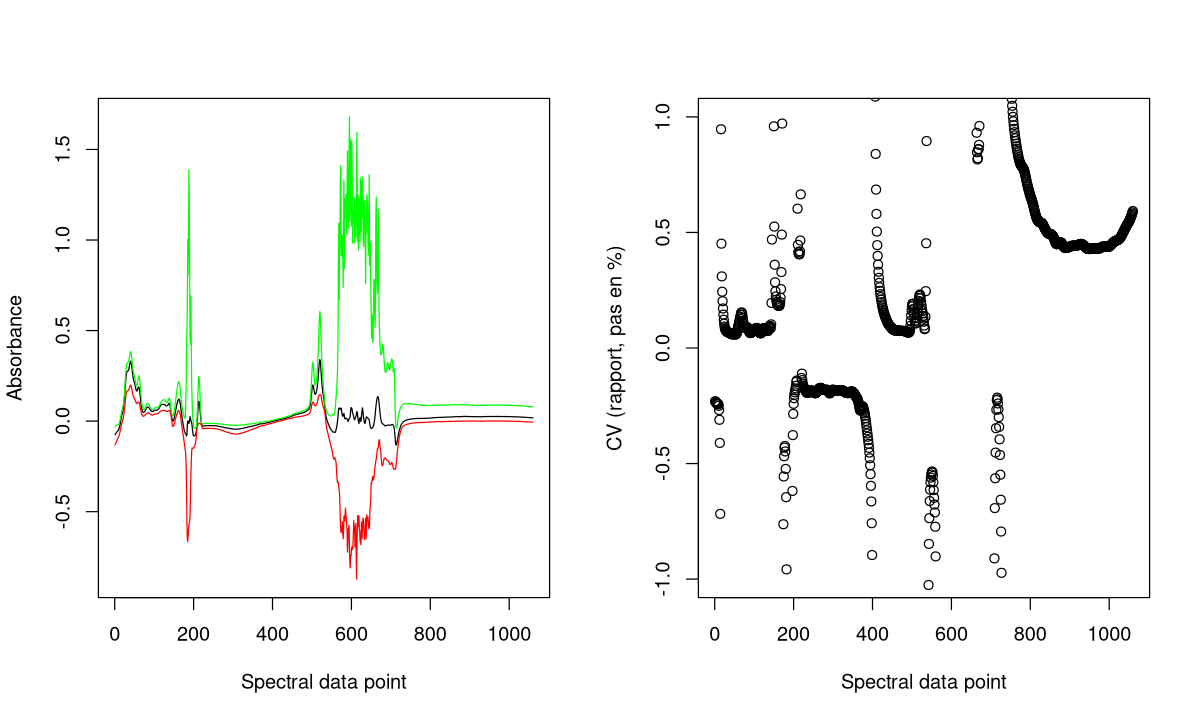

In [49]:
xmin <- c(); xmax <- c(); xmean <- c(); xCV <- c()
for (i in 1:1060) {
  col <- X[, i]                  # variable intermédiaire : évite les messages de summarytools
  tmp <- descr(col)
  xmin[i]  <- tmp[3]
  xmax[i]  <- tmp[7]
  xmean[i] <- tmp[1]
  xCV[i]   <- tmp[10]
}

par(mfrow = c(1, 2))
plot(x = c(1:1060), y = xmean, type = "l", ylim = range(c(xmin, xmax)), xlab = "Spectral data point", ylab = "Absorbance")
lines(xmin, col = "red")
lines(xmax, col = "green")
plot(x = c(1:1060), xCV, ylim = c(-1, 1), xlab = "Spectral data point", ylab = "CV (rapport, pas en %)")
par(mfrow = c(1, 1))

Remarques :

- le CV de `descr()` est un **rapport** (0.36 = 36 %), d'où `ylim = c(-1, 1)` dans le script, alors que la correction (B3) calcule le CV en %, avec un seuil à 50 % ;
- la boucle n'est pas indispensable : R sait calculer une statistique pour toutes les colonnes d'un coup.

[1] TRUE

[1] TRUE

[1] TRUE

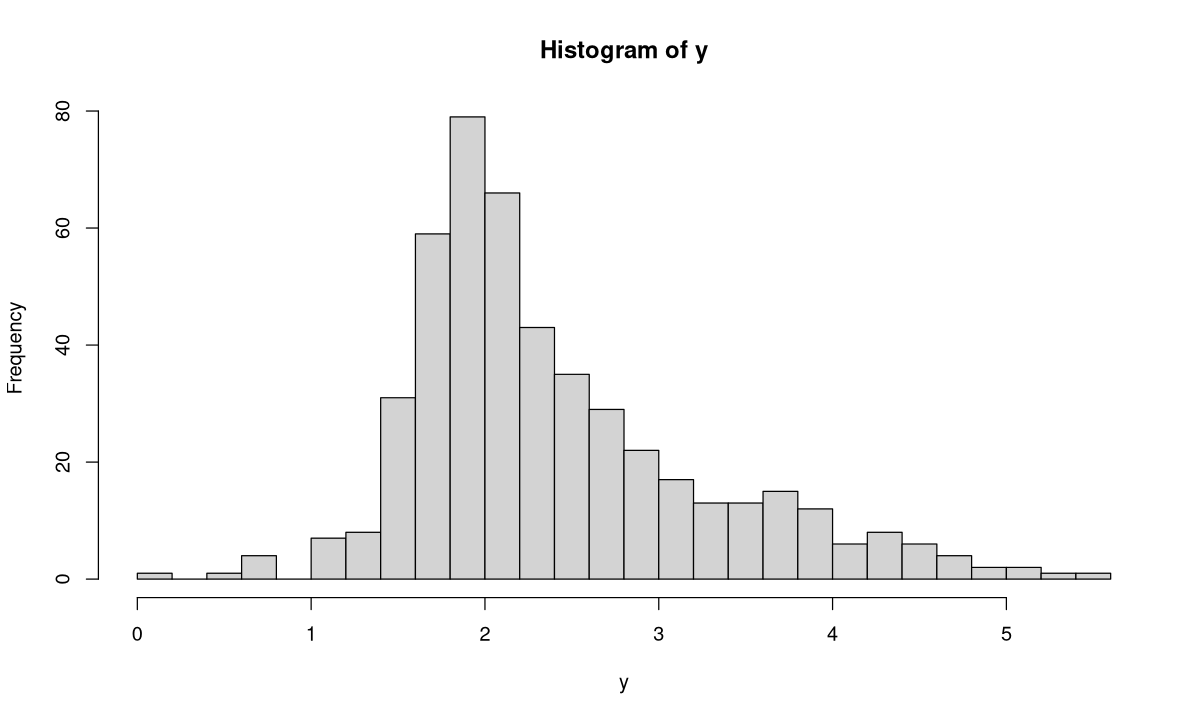

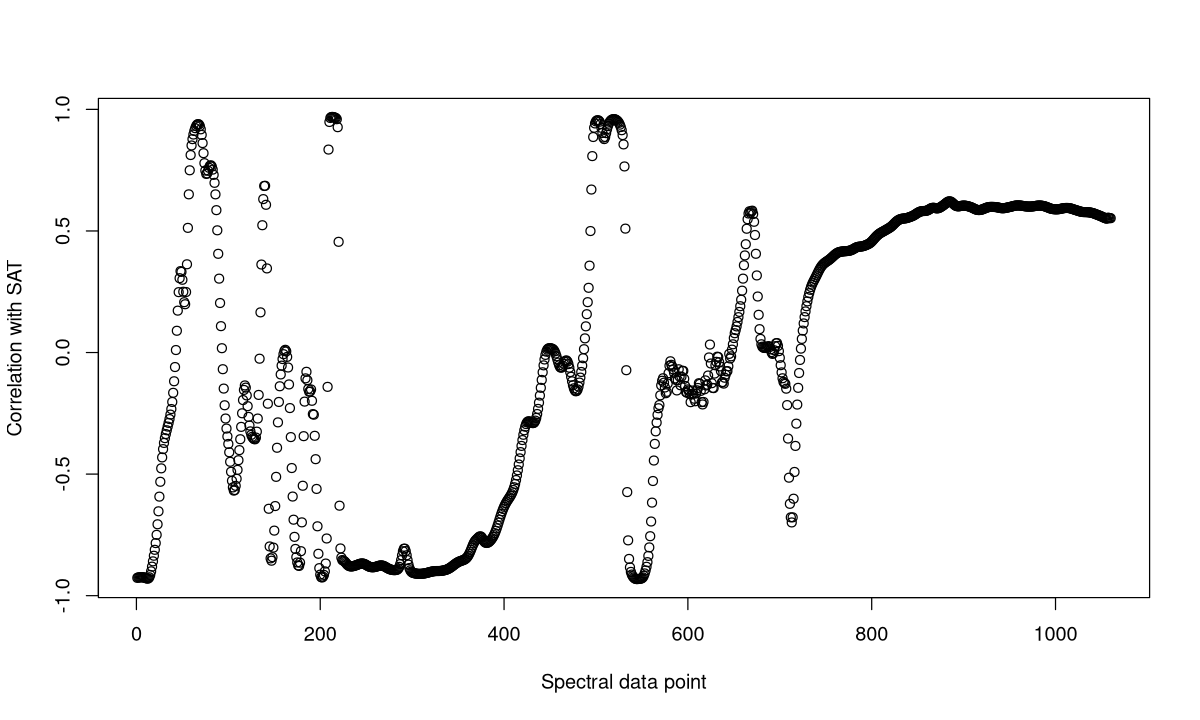

In [50]:
# Équivalents vectorisés, instantanés
all.equal(xmean, unname(colMeans(X)))                    # moyenne par colonne
all.equal(xmin,  unname(apply(X, 2, min)))               # apply(X, 2, f) : f appliquée à chaque colonne
all.equal(xCV,   unname(apply(X, 2, sd) / colMeans(X)))  # CV = sd / moyenne

hist(y, breaks = 30)

# Corrélation de chaque point spectral avec SAT
corr_X_sat <- cor(y, X)          # matrice 1 x 1060
plot(x = c(1:1060), corr_X_sat, xlab = "Spectral data point", ylab = "Correlation with SAT")

### C2. Lasso et Ridge sur le spectre complet

> **glmnet et les data.frames** : la documentation de `glmnet()` demande une **matrice** pour `x`. Le script passe `X`, qui est un **data.frame**. Avec la version installée ici (glmnet 5.1), cela **fonctionne** : glmnet convertit lui-même le data.frame. Mais d'anciennes versions renvoyaient une erreur ; par sécurité et par clarté, écris toujours `as.matrix(X)` (c'est ce que font la partie A et la correction officielle).

[1] ‘5.1’

[1] "elnet"  "glmnet"


Call:  glmnet(x = X, y = y, family = "gaussian", alpha = 1, lambda = c(5,      2, 1, 0.5, 0.1, 0.01, 0.001)) 

   Df  %Dev Lambda
1   0  0.00  5.000
2   0  0.00  2.000
3   0  0.00  1.000
4   1 59.86  0.500
5   9 93.43  0.100
6  28 96.47  0.010
7 112 98.88  0.001

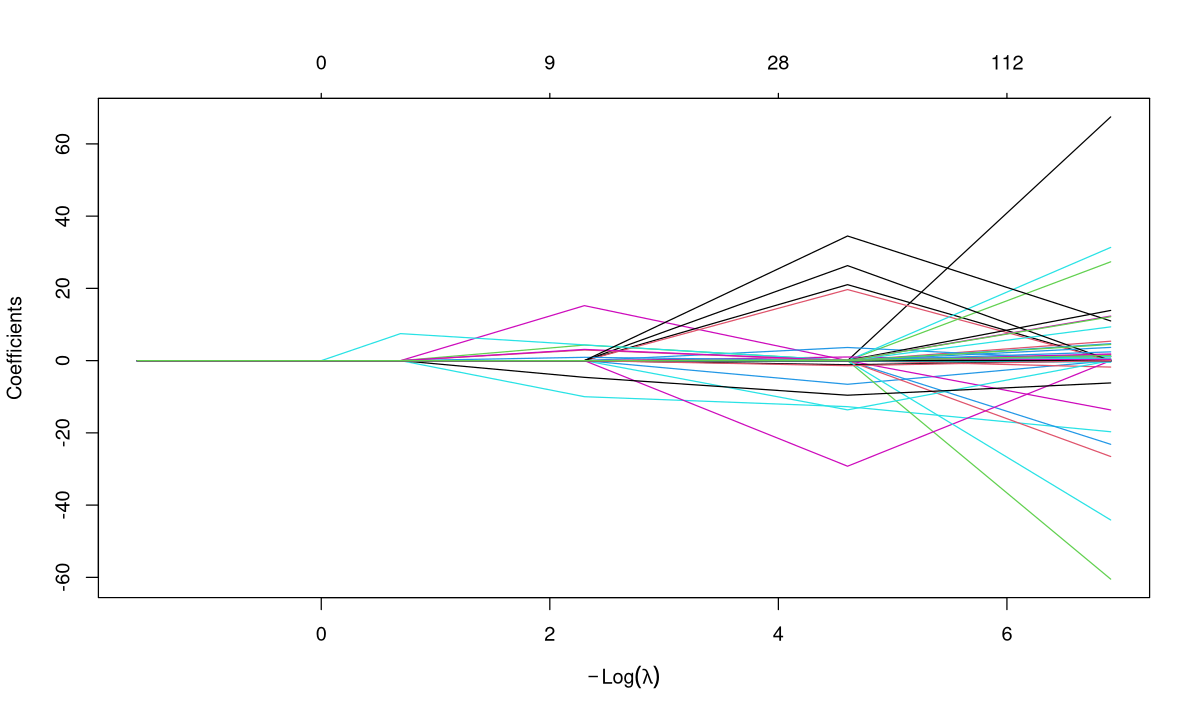

In [51]:
packageVersion("glmnet")
mod1 <- glmnet(x = X, y = y, family = "gaussian", alpha = 1, lambda = c(5, 2, 1, 0.5, 0.1, 0.01, 0.001))
class(mod1)        # l'appel avec un data.frame a fonctionné
mod1
plot(mod1)         # xvar = "norm" par défaut

Avec le Lasso, aucun point n'est retenu pour λ ≥ 1 ; **un seul** pour λ = 0.5 (60 % de déviance expliquée) ; 9 pour λ = 0.1 ; 28 pour 0.01 ; 112 pour 0.001.

Le script ajuste ensuite un Lasso pour λ = 0.5 seulement et cherche le coefficient non nul :

In [52]:
mod2 <- glmnet(x = as.matrix(X), y = y, family = "gaussian", alpha = 1, lambda = 0.5)
mycoef <- coef(mod2)[coef(mod2) != 0]
which(coef(mod2) != 0)            # positions 1 et 214
mycoef
mod2$beta[coef(mod2) != 0]        # renvoie 0 0 : indexation décalée !

[1]   1 214

[1] 1.592173 7.475362

[1] 0 0

### Exercice C2 : le décalage de l'intercept

1. `which(coef(mod2) != 0)` renvoie 1 et 214 : à quelles variables correspondent ces positions ?
2. Pourquoi `mod2$beta[coef(mod2) != 0]` renvoie-t-il `0 0` au lieu du coefficient ? Corrige l'extraction pour obtenir **le nom et la valeur** du point spectral sélectionné.

In [53]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
rownames(coef(mod2))[which(coef(mod2) != 0)]   # "(Intercept)" "X213"
b <- mod2$beta[, 1]                            # coefficients sans l'intercept (1060 valeurs)
b[b != 0]                                      # X213 : le point retenu et sa valeur
# ou : cf <- coef(mod2)[-1, 1]; cf[cf != 0]
```

1. `coef()` renvoie **1061** lignes : l'intercept en position 1, puis les 1060 points. La position 214 est donc le point **X213** (214 − 1).
2. `mod2$beta` ne contient **que** les 1060 pentes (pas d'intercept). Le vecteur logique `coef(mod2) != 0` est de longueur 1061 et **décalé d'une position** : il désigne les éléments 1 et 214 de `beta`, c'est-à-dire X1 et X214, qui valent 0. Il faut toujours construire le filtre sur le **même objet** que celui qu'on indexe.

Le Lasso retient X213 en premier : c'est exactement le point le plus corrélé à SAT trouvé à l'étape 4 de la partie A.

</details>

In [54]:
# Ridge sur le spectre complet
mod3 <- glmnet(x = as.matrix(X), y = y, family = "gaussian", alpha = 0, lambda = c(5, 2, 1, 0.5, 0.1, 0.01, 0.001))
mod3

# Régression linéaire sur le point 213
mod4 <- lm(y ~ X[, 213])
summary(mod4)


Call:  glmnet(x = as.matrix(X), y = y, family = "gaussian", alpha = 0,      lambda = c(5, 2, 1, 0.5, 0.1, 0.01, 0.001)) 

    Df  %Dev Lambda
1 1060 93.91  5.000
2 1060 95.26  2.000
3 1060 96.12  1.000
4 1060 96.82  0.500
5 1060 97.93  0.100
6 1060 99.12  0.010
7 1060 99.33  0.001


Call:
lm(formula = y ~ X[, 213])

Residuals:
     Min       1Q   Median       3Q      Max 
-0.77463 -0.13277  0.01137  0.13972  0.63460 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)  0.36499    0.02547   14.33   <2e-16 ***
X[, 213]    18.79158    0.21749   86.40   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.2116 on 483 degrees of freedom
Multiple R-squared:  0.9392,	Adjusted R-squared:  0.9391 
F-statistic:  7465 on 1 and 483 DF,  p-value: < 2.2e-16


**Lecture** :

- **Ridge** : `Df = 1060` pour **tous** les λ (aucun coefficient nul) et une déviance expliquée déjà de 94 % à λ = 5, alors que le Lasso, au même λ, n'a encore retenu aucune variable. Les deux échelles de λ ne sont pas comparables (pénalités différentes, cf. partie 6, §6.6.3) ;
- `lm(y ~ X[, 213])` : `X[, 213]` est la 213e colonne de X, c'est-à-dire le **point X213** (pas de décalage ici, car X ne contient que le spectre). R² ≈ **0.939** : c'est la régression univariée de la partie A (étape 4).

---

# PARTIE D : Comparaison des deux démarches

On compare les modèles finaux de la **partie A** (script `homework1.R`) et de la **partie B** (correction officielle). La cellule suivante recrée tout ce qu'il faut (y compris le modèle `best` sauvegardé à l'étape 11), au cas où tu n'aurais pas tout exécuté.

In [55]:
# Point de contrôle : reconstruction des modèles à comparer
perf <- function(mod) {
  c(n_obs = length(resid(mod)), k = length(coef(mod)) - 1, R2 = summary(mod)$r.squared,
    adjR2 = summary(mod)$adj.r.squared, SEP = sqrt(sum(resid(mod)^2) / mod$df.residual))
}
ySAT    <- fattyacid$SAT
uni_X213 <- lm(ySAT ~ fattyacid$X213)          # partie A étape 4 = mod4 de la partie C
load("best_model_SAT.RData")                    # partie A étape 11 : objet best

comparaison <- rbind(
  "A. univariée X213 (= script TP 2026)"          = perf(uni_X213),
  "A. Lasso λ=0.002 → Cook 4/n → backward (best)" = perf(best),
  "B. 14 features (1re/dernière par région)"      = perf(regSAT),
  "B. 12 features (regSAT2)"                      = perf(regSAT2),
  "B. lm sur Lasso λ=0.01"                        = perf(reg_lasso[["0.01"]]),
  "B. lm sur Lasso λ=0.001"                       = perf(reg_lasso[["0.001"]]),
  "B. lm sur Lasso λ=1e-04"                       = perf(reg_lasso[["1e-04"]])
)
kable(comparaison, digits = 4)



|                                              | n_obs|   k|     R2|  adjR2|    SEP|
|:---------------------------------------------|-----:|---:|------:|------:|------:|
|A. univariée X213 (= script TP 2026)          |   485|   1| 0.9392| 0.9391| 0.2116|
|A. Lasso λ=0.002 → Cook 4/n → backward (best) |   449|  43| 0.9956| 0.9951| 0.0577|
|B. 14 features (1re/dernière par région)      |   485|  14| 0.9665| 0.9655| 0.1593|
|B. 12 features (regSAT2)                      |   485|  12| 0.9665| 0.9656| 0.1590|
|B. lm sur Lasso λ=0.01                        |   485|  12| 0.9630| 0.9621| 0.1670|
|B. lm sur Lasso λ=0.001                       |   485|  62| 0.9909| 0.9896| 0.0874|
|B. lm sur Lasso λ=1e-04                       |   485| 191| 0.9971| 0.9952| 0.0594|

### Avantages et limites

| | Partie A : `homework1.R` | Partie B : correction officielle |
|---|---|---|
| Point de départ | toutes les features (Lasso sur les 1060 points) | spectre **nettoyé** (CV ≤ 50 %) puis filtré sur \|r\| |
| Gestion de la colinéarité | le Lasso choisit parmi des points corrélés, puis backward | choix **manuel** d'1 à 2 points par région spectrale |
| Outliers | 36 échantillons retirés (Cook > 4/n) | aucun retiré (seulement signalés) |
| Modèle final | **43** features, n = 449, R² ≈ 0.996, SEP ≈ 0.058 g/dl | **12** features, n = 485, R² ≈ 0.967, SEP ≈ 0.159 g/dl |
| Avantages | erreur de calibration très faible ; démarche automatique et reproductible | modèle **parcimonieux** et **interprétable** (une feature par région) ; tous les échantillons conservés ; coefficients plus stables |
| Limites | 43 variables encore colinéaires ; 7 % des échantillons retirés : le modèle ne « voit » pas les cas atypiques ; R² gonflé par le retrait des outliers ; fort risque de **surajustement** | filtre CV discutable (CV ≤ 50 sans `abs`, CV peu fiable si moyenne ≈ 0) ; choix des régions et des points en partie **subjectif** ; X0070 et X0200 à p ≈ 0.08 |

**À retenir**

- Les R², R² ajustés et SEP de ce tableau sont **tous des performances de calibration** : ils sont calculés sur les données qui ont servi à choisir les variables et à estimer les coefficients. Ils **surestiment** la qualité de prédiction sur de nouveaux échantillons, d'autant plus que le modèle a de variables et que des échantillons ont été retirés.
- Les modèles de la partie A (`best`, n = 449) et de la partie B (n = 485) ne sont même pas évalués sur les mêmes échantillons : la comparaison directe des SEP est **biaisée en faveur de la partie A**.
- Le seul arbitre honnête est une **validation sur des échantillons indépendants** (RMSEP), qui sera vue au **module 2**. En attendant, à performance de calibration proche, on préfère le modèle **le plus parcimonieux**.

### Question de synthèse

Si tu devais déployer l'une de ces équations en routine dans un laboratoire d'analyse du lait, laquelle choisirais-tu aujourd'hui et quelle étape ajouterais-tu avant ?

<details>
<summary><b>Voir la réponse</b></summary>

Avant toute chose : **valider** les équations candidates sur un jeu d'échantillons **indépendant** (idéalement d'autres troupeaux, d'autres périodes, d'autres spectromètres) et comparer leurs **RMSEP**. Sans cette validation, le choix le plus prudent est le modèle **parcimonieux** de la correction (`regSAT2`, 12 features, tous les échantillons conservés) : moins de variables, donc un moindre risque de surajustement et une meilleure robustesse attendue sur de nouveaux échantillons. Le modèle `best` (43 features, outliers retirés) n'est à préférer que s'il confirme sa supériorité en validation.

</details>

---

## Récapitulatif du TP

**Partie A : la démarche complète (à savoir refaire à l'examen : script + rapport)**

| Étape | Action | Fonctions clés |
|---|---|---|
| 1 | Lecture | `read.table(file, sep, header)`, `dim`, `names`, `str` |
| 2 | Statistiques descriptives | `descr(transpose = TRUE)`, `pander`, `hist` |
| 3 | Transformations de y | `log10`, `sqrt`, `par(mfrow)` |
| 4 | Régression univariée | `cor(X, y)`, `order(abs())`, `lm`, `summary`, R², SEP, R² ajusté |
| 5 | Analyse des résidus | `plot(lm)`, `shapiro.test(resid())`, `plot(lm, which = 4)` |
| 6 | Multivariée 10 features | `lm(y ~ x)` avec x matrice ; colinéarité `cor(x)` |
| 7 | Sélection de variables | `paste0`, `as.formula`, `ols_step_all_possible`, `stepAIC(direction, scope)` |
| 8 | Lasso sur tout le spectre | `glmnet(alpha = 1, lambda)`, `$beta`, `$lambda`, fonction `perf` |
| 9 | Outliers | `cooks.distance`, seuil 4/n (ou 1) |
| 10 | Modèle final | `lm(y ~ ., data)`, `stepAIC(backward)`, `perf` |
| 11 | Sauvegarde | `save`, `load`, `predict(newdata)` |

**Résultats clés (SAT)** : point le plus corrélé X213 (r ≈ 0.97, R² univarié ≈ 0.94, SEP ≈ 0.21 g/dl) ; y non transformé (log10 et sqrt dégradent la normalité des résidus) ; modèle final : 71 points sélectionnés par le Lasso (λ = 0.002) → 36 outliers retirés (Cook > 4/n) → backward : **43 points, R² ≈ 0.996, SEP ≈ 0.058 g/dl** (performances de **calibration** : la validation viendra au module 2).

**Partie B : correction officielle** : spectre renommé `X0001…X1060` (sinon `descr()` trie les colonnes par ordre alphabétique) → CV par point, filtre `CV <= 50` → **809** features (le texte parle de |CV|, ce qui donnerait 687) → |r| > 0.9 avec SAT → **104** features → une feature au début et une à la fin de chacune des 7 régions → **14** features → retrait de X0219 et X0299 → `regSAT2` : **12 features, R² ≈ 0.967, R² ajusté ≈ 0.966, SEP ≈ 0.159 g/dl**, n = 485. Lasso sur les **406** features à |r| > 0.6 : glmnet **trie la grille de λ** par ordre décroissant, donc il faut désigner un λ par sa **valeur**, pas par un numéro de colonne de `beta`.

**Partie C : script TP 2026** : `read.csv`, boucle `descr` (passer par une variable intermédiaire), équivalents vectorisés `colMeans` / `apply` ; glmnet 5.1 accepte un data.frame, mais écris `as.matrix()` ; attention au décalage de l'intercept entre `coef()` (1061 lignes) et `$beta` (1060 lignes) ; le Lasso à λ = 0.5 retient X213, le point le plus corrélé.

**Partie D** : modèle A, 43 features (R² ≈ 0.996 sur 449 échantillons) contre modèle B, 12 features (R² ≈ 0.967 sur 485) : ce sont **uniquement des performances de calibration**. Le choix final demande une **validation indépendante (module 2)** ; d'ici là, on préfère la **parcimonie**.

| Fonctions supplémentaires (parties B-C) | Rôle |
|---|---|
| `sprintf("X%04d", 1:1060)` | noms à nombre de chiffres fixe |
| `descr(df, stats = "common", transpose = TRUE)` | statistiques de toutes les colonnes |
| `corrplot(abs(cor(X)), method = "color", tl.pos = "n")` | carte de chaleur des corrélations |
| `diff()`, `sub()`, `as.integer()` | détection automatique des régions spectrales |
| `lasso.mod$beta[, lasso.mod$lambda == l]`, `coef(mod, s = l)` | coefficients pour un λ désigné par sa valeur |
| `colMeans()`, `apply(X, 2, f)` | statistiques par colonne sans boucle |
| `read.csv(file, sep, header)` | lecture d'un fichier texte délimité |

**Suite** : la partie 8 propose une synthèse et un aide-mémoire de tout le module.